# Riemannian flow matching on a swiss roll

This notebook repeats the analysis of the annulus notebook (`riemannian_toy_example.ipynb`) on a two-dimensional **swiss roll**: a strip of constant width wound along an Archimedean spiral. The source cloud sits at the **outer end** of the roll and the target cloud at its **inner end**, so every source–target pair is joined inside the domain only by winding around the roll. Straight Euclidean chords cut across the gaps between the turns.

The reusable code lives in the `riemannian_toys` package next to it (run the notebook from `docs/notebooks`):

| Module | Content |
| --- | --- |
| `riemannian_toys.swiss_roll` | spiral strip: sampling, projection, edge/end-cap tangent-cone guard, domain diagnostics, drawing |
| `riemannian_toys.kernels` | kernel-profile fits, raw-field checks, Euler trajectories, refinement |
| `riemannian_toys.flows` | toy AnnData, OT matching, training, prediction, learned fields and paths |
| `riemannian_toys.comparison` | the four-way coupling × interpolation comparison |
| `riemannian_toys.reference_paths` | FM/RFM conditional reference paths vs. exact geodesics: Hausdorff, Chamfer, Wasserstein |
| `riemannian_toys.loss_modes` | final-point vs. trajectory RFM loss, single run and multi-seed |
| `riemannian_toys.plotting` | figures |

Library pieces it builds on: `cellflow.preprocessing.fit_kernel_nystroem` and `cellflow.ode_solver.GuardedRFMInterpolation`.

In [1]:
import jax
import jax.numpy as jnp
import numpy as np
import optax
import pandas as pd
from IPython.display import display
from scipy.spatial.distance import cdist

from riemannian_toys import comparison, flows, kernels, loss_modes, plotting, reference_paths
from riemannian_toys.swiss_roll import SwissRoll

/home/markus/university/adlr/CellFlow/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## The swiss roll

The centerline is the Archimedean spiral
$$c(\theta)=r(\theta)\,(\cos\theta,\sin\theta),\qquad r(\theta)=r_0+\frac{p\,\theta}{2\pi},\qquad \theta\in[0,\theta_{\max}],$$
with inner radius $r_0=1$, pitch $p=1.2$ (radial distance between neighboring turns) and $\theta_{\max}=3\pi$ (1.5 turns). The roll is the strip $\{\rho\,e(\theta):|\rho-r(\theta)|\le w\}$ with half-width $w=0.3$. The pitch exceeds the strip width $2w$, so the turns are separated by gaps of width $p-2w=0.6$, and every point of the plane belongs to at most one turn. $\theta=0$ is the inner end at $(1,0)$; $\theta_{\max}$ is the outer end at $(-2.8,0)$. The centerline is about 18 units long, whereas the two ends are less than 4 units apart in the plane.

Centerline length: 18.01; outer radius: 2.80; gap between turns: 0.60


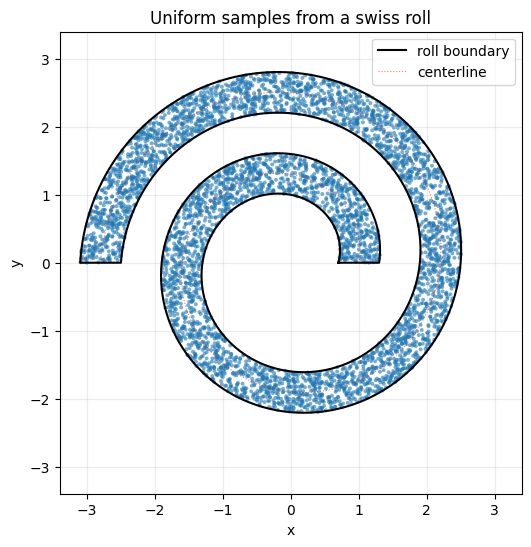

In [2]:
# Uniform sampling from the 2D swiss roll: |rho - r(theta)| <= 0.3, 1.5 turns
roll = SwissRoll(inner_radius=1.0, pitch=1.2, half_width=0.3, turns=1.5)
half_width = roll.half_width
n_points = 5_000
points = roll.sample_uniform(n_points, np.random.default_rng(42))
print(f"Centerline length: {roll.centerline_length:.2f}; outer radius: {roll.outer_radius:.2f}; "
      f"gap between turns: {roll.pitch - 2 * half_width:.2f}")

plotting.plot_point_clouds(
    roll, [(points, {"s": 8, "alpha": 0.6, "edgecolors": "none"})],
    "Uniform samples from a swiss roll", figsize=(6, 6), label_boundaries=True,
)

Outer Gaussian retained 250 points; acceptance rate in generated batches: 67.78%
Inner Gaussian retained 250 points; acceptance rate in generated batches: 68.18%


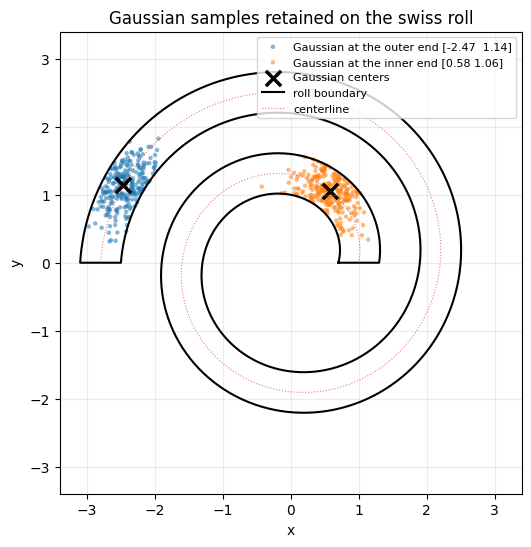

In [3]:
# Gaussian datasets conditioned to lie on the roll, each within half a turn of its end.
# The angle window keeps a cloud from leaking onto the neighboring turn across the gap.
rng = np.random.default_rng(123)
variance = 0.09
n_points_per_gaussian = 250
end_offset = 1.2  # centerline arc length between each Gaussian center and its end of the roll
mean_outer = roll.strip_point(roll.theta_at_arc_length(roll.centerline_length - end_offset))
mean_inner = roll.strip_point(roll.theta_at_arc_length(end_offset))
outer_window = (roll.theta_max - np.pi, roll.theta_max)
inner_window = (0.0, np.pi)

outer_gaussian_points, outer_drawn, outer_accepted = roll.sample_gaussian(
    mean_outer, variance, n_points_per_gaussian, rng, theta_window=outer_window)
inner_gaussian_points, inner_drawn, inner_accepted = roll.sample_gaussian(
    mean_inner, variance, n_points_per_gaussian, rng, theta_window=inner_window)
gaussian_roll_points = np.vstack((outer_gaussian_points, inner_gaussian_points))
gaussian_roll_labels = np.repeat([0, 1], n_points_per_gaussian)

print(f"Outer Gaussian retained {n_points_per_gaussian} points; acceptance rate in generated batches: {outer_accepted / outer_drawn:.2%}")
print(f"Inner Gaussian retained {n_points_per_gaussian} points; acceptance rate in generated batches: {inner_accepted / inner_drawn:.2%}")
plotting.plot_point_clouds(roll, [
    (outer_gaussian_points, {"s": 10, "alpha": 0.55, "edgecolors": "none", "label": f"Gaussian at the outer end {np.round(mean_outer, 2)}"}),
    (inner_gaussian_points, {"s": 10, "alpha": 0.55, "edgecolors": "none", "label": f"Gaussian at the inner end {np.round(mean_inner, 2)}"}),
    (np.vstack((mean_outer, mean_inner)), {"marker": "x", "s": 120, "linewidths": 2.5, "color": "black", "label": "Gaussian centers"}),
], "Gaussian samples retained on the swiss roll", label_boundaries=True, legend_fontsize=8)

## Construction data for the kernel-profile comparison

The uniform roll samples define the shared construction set for all five kernels. The Gaussian clouds provide starting points and visual context. Each profile is fitted on the same symmetric CkNN support, then supplies a Laplacian, biharmonic spectral embedding, continuous Nyström extension, and RFM vector field. The experiment compares raw and boundary-guarded trajectories and checks their behavior when the Euler step size is halved.

all_generated_points shape: (5500, 2)
construction_points shape: (5000, 2)
construction source: uniform roll samples only
source counts:
  uniform roll: 5000
  outer Gaussian: 250
  inner Gaussian: 250


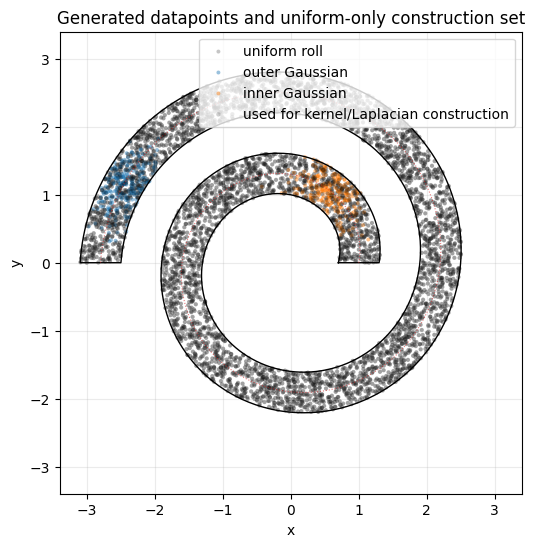

In [4]:
all_generated_points = np.vstack((points, gaussian_roll_points))
construction_points = points.astype(np.float32)
source_labels = np.concatenate((
    np.full(points.shape[0], "uniform roll", dtype=object),
    np.where(gaussian_roll_labels == 0, "outer Gaussian", "inner Gaussian").astype(object),
))
source_palette = {"uniform roll": "tab:gray", "outer Gaussian": "tab:blue", "inner Gaussian": "tab:orange"}

print("all_generated_points shape:", all_generated_points.shape)
print("construction_points shape:", construction_points.shape)
print("construction source: uniform roll samples only")
print("source counts:")
for label in source_palette:
    print(f"  {label}: {np.sum(source_labels == label)}")
plotting.plot_point_clouds(roll, [
    *[(all_generated_points[source_labels == label], {"s": 8, "alpha": 0.45, "edgecolors": "none", "color": color, "label": label})
      for label, color in source_palette.items()],
    (construction_points, {"s": 10, "alpha": 0.18, "edgecolors": "none", "color": "black",
                           "label": "used for kernel/Laplacian construction"}),
], "Generated datapoints and uniform-only construction set")

### Shared roll projection and boundary helpers

Every profile uses the same roll geometry and boundary probes. The point projection maps a point to the nearest turn: for each candidate turn it clips the roll angle to $[0,\theta_{\max}]$ and the radial coordinate to $[r(\theta)-w,\,r(\theta)+w]$, then keeps the closest candidate. Inside the roll this is the identity; outside it is the closest point up to the slope of the spiral. The roll is two-dimensional in its two-dimensional ambient space, so the interior tangent-space projection is the identity. The boundary has two long edges and two end caps. At a boundary point, the tangent-cone guard removes velocity pointing out across the active edge or cap, and keeps inward and tangential components. The raw trajectories evaluate the analytical field directly; the guarded trajectories use this common cone guard and project after every Euler step.

In [5]:
# `roll.project` maps to the nearest turn; `roll.guard_velocity` is the tangent-cone guard.
# `roll.guarded_interpolator(model)` combines both in a GuardedRFMInterpolation.
project_to_roll = roll.project
boundary_points, boundary_normals = roll.probe_points, roll.probe_normals

probe_velocity = -np.asarray(boundary_normals)  # pointing out of the roll everywhere
guarded_velocity = np.asarray(roll.guard_velocity(boundary_points, probe_velocity))
print(f"{len(boundary_points)} boundary probes (edges and end caps); outward velocity left after the guard: "
      f"{np.abs(np.minimum(np.sum(guarded_velocity * boundary_normals, axis=1), 0)).max():.2e}")

202 boundary probes (edges and end caps); outward velocity left after the guard: 3.98e-13


## Symmetric variable-bandwidth kernels: fields and trajectories

This comparison uses the same uniform construction points and CkNN support for every profile:
$\rho_i=\|x_i-x_{i,k_\rho}\|$, $s_{ij}=\|x_i-x_j\|^2/(\delta^2\rho_i\rho_j)$, with edges where $s_{ij}<1$. We compare a fixed-bandwidth Gaussian on this support, a self-tuning Gaussian, $(1-s)_+^4$, a smooth bump, and binary CkNN. Gaussian profiles are truncated here; setting compact_support=False also implements the full Gaussian reference.

| Profile | Weight on a CkNN edge ($s<1$) |
| --- | --- |
| Fixed Gaussian | $\exp(-\|x-y\|^2/(2\sigma^2))$ |
| Variable Gaussian | $\exp(-s/2)$ |
| Compact polynomial | $(1-s)^4$ |
| Smooth bump | $\exp(1-1/(1-s))$ |
| Binary CkNN | $1$ |

The shared support uses kernel_density_k=24 and kernel_delta=2.0. All profiles share construction points, edge candidates, spectral weighting, field probes, starting points, targets, and integration steps. The fixed Gaussian bandwidth is the median positive distance across the 24 non-self nearest neighbors of the construction points. Smooth profiles can lose extremely small weights to underflow; the table reports their retained edges.

By default we use $L=D-W$, matching [Berry and Sauer, Section 6](https://math.gmu.edu/~berry/Publications/CkNN.pdf#page=23). Set kernel_laplacian_type="normalized" to compare the normalized Laplacian. The Nyström formulas, including spectral scales $a_\ell$, are

$$
\Psi_\ell(x)=
\begin{cases}
a_\ell\displaystyle\frac{\sum_jw_j(x)\phi_{j\ell}}{d(x)-\lambda_\ell}, & L=D-W,\\[8pt]
a_\ell\displaystyle\frac{\sum_jw_j(x)\phi_{j\ell}/\sqrt{d_j}}{\sqrt{d(x)}(1-\lambda_\ell)}, & L=I-D^{-1/2}WD^{-1/2}.
\end{cases}
$$

Analytic gradients differentiate both $d(x)$ and $\rho(x)$. Query scales use the $(k_\rho+1)$th training point, including a possible self-match, so they continuously reproduce the fitted non-self scales at training coordinates. This scale estimator is piecewise smooth at neighbor ties. Normalized graphs retain self-affinities for agreement with the continuous extension; self-affinities cancel from $D-W$.

Binary CkNN has zero extension gradients almost everywhere and therefore produces stationary RFM trajectories. Truncated Gaussians have support-boundary jumps. The polynomial and bump remove those jumps, while retaining possible derivative changes from the bandwidth estimator. Numerical derivative checks and training-coordinate reconstruction are reported before the flow comparison.

In [6]:
kernel_density_k = 24
kernel_delta = 2.0
kernel_n_modes = 32
kernel_laplacian_type = "unnormalized"
kernel_spectral_weight_type = "biharmonic"

kernel_models, kernel_fitted, kernel_graphs, kernel_fit_df = kernels.fit_kernel_profiles(
    construction_points, kernels.KERNEL_PROFILES, density_k=kernel_density_k, delta=kernel_delta,
    n_modes=kernel_n_modes, laplacian_type=kernel_laplacian_type, spectral_weight_type=kernel_spectral_weight_type,
)
display(kernel_fit_df)

fixed Gaussian: fitted in 1.11s


variable Gaussian: fitted in 0.48s


compact polynomial: fitted in 0.57s


smooth bump: fitted in 0.55s


binary CkNN: fitted in 0.52s


,edges,components,min_degree,median_degree,lambda_2,max_eigen_residual,extension_relative_error,fit_seconds,retained_edge_fraction
kernel,,,,,,,,,
fixed Gaussian,211019,1,7.837295,22.508793,0.002460,7.774151e-14,7.759641e-08,1.111404,1.000000
variable Gaussian,211019,1,38.941018,66.586387,0.017850,2.039896e-13,8.638381e-08,0.483565,1.000000
compact polynomial,211019,1,10.962989,18.568033,0.001715,1.119762e-10,9.860767e-08,0.574446,1.000000
smooth bump,208883,1,20.545028,36.709226,0.005398,1.664621e-11,8.669161e-08,0.554350,0.989878
binary CkNN,211019,1,47.000000,83.000000,0.024589,2.567598e-13,7.038057e-08,0.522163,1.000000


,median_speed,p95_speed,zero_speed_fraction,unsupported_probe_fraction,outward_boundary_fraction,autodiff_relative_error,finite_difference_relative_error
kernel,,,,,,,
fixed Gaussian,15.022900,164.807281,0.0,0.0,0.361386,8.525155e-16,1.014320e-09
variable Gaussian,60.900089,561.868774,0.0,0.0,0.490099,3.058585e-15,5.975367e-09
compact polynomial,14.344768,127.156960,0.0,0.0,0.480198,3.965276e-15,9.808097e-10
smooth bump,14.854885,135.225754,0.0,0.0,0.490099,7.487248e-16,2.533605e-09
binary CkNN,0.000000,0.000000,1.0,0.0,0.000000,0.000000e+00,0.000000e+00


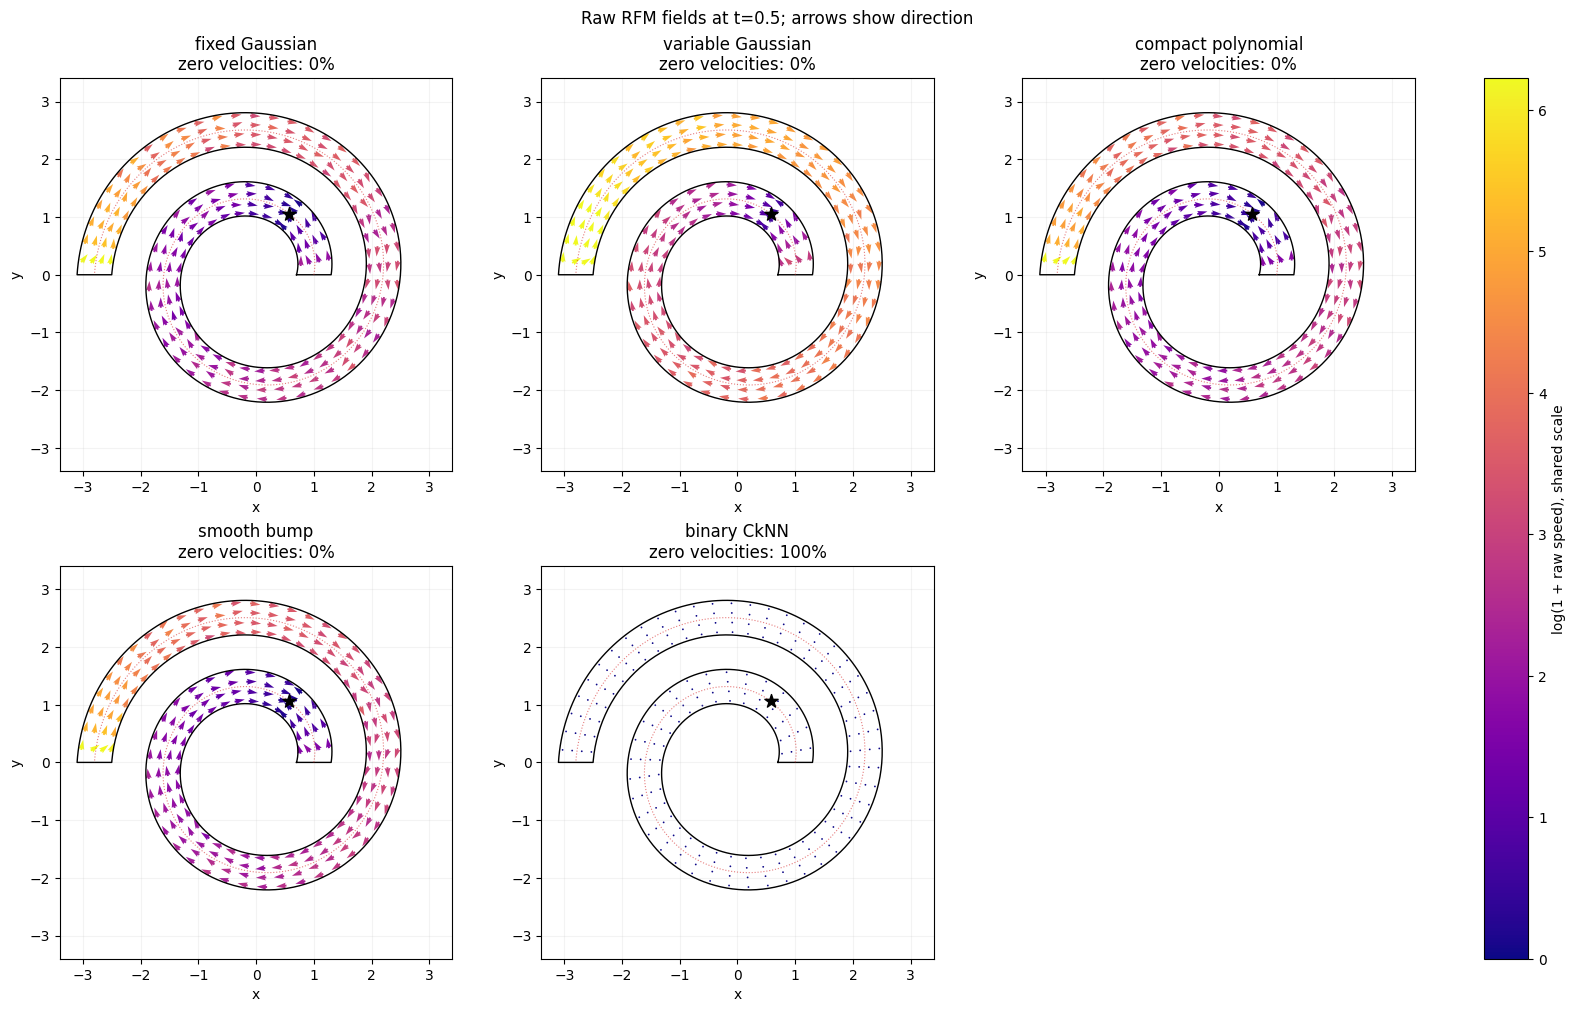

In [7]:
kernel_field_points = roll.field_grid(n_along=60, n_across=4)
kernel_target = mean_inner.astype(np.float32)
kernel_field_time = 0.5

kernel_fields, kernel_field_df = kernels.raw_field_diagnostics(
    kernel_models, kernel_fitted, roll, kernel_field_points, kernel_target, kernel_field_time,
    gradient_query=roll.strip_point(roll.theta_at_arc_length(0.5 * roll.centerline_length), 0.07),
)
display(kernel_field_df)
plotting.plot_kernel_fields(roll, kernel_field_points, kernel_fields, kernel_target, kernel_field_time)

In [8]:
kernel_start_ids = np.random.default_rng(2026).choice(len(outer_gaussian_points), 12, replace=False)
kernel_starts = outer_gaussian_points[kernel_start_ids].astype(np.float32)
kernel_final_time = 0.99
kernel_integration_steps = 800
kernel_step_times = np.linspace(0.0, kernel_final_time, kernel_integration_steps + 1, dtype=np.float32)

kernel_trajectories, kernel_distance_traces, kernel_trajectory_df = kernels.trajectory_comparison(
    kernel_models, kernel_fitted, roll, kernel_starts, kernel_target, kernel_final_time, kernel_integration_steps,
)
display(kernel_trajectory_df.sort_values(["mode", "mean_final_euclidean"]).reset_index(drop=True))

fixed Gaussian, unprojected: mean endpoint error 0.1729, 0% within 0.1; 11.38s


fixed Gaussian, roll + cone: mean endpoint error 0.1729, 0% within 0.1; 17.74s


variable Gaussian, unprojected: mean endpoint error 0.0668, 75% within 0.1; 11.26s


variable Gaussian, roll + cone: mean endpoint error 0.0784, 75% within 0.1; 17.01s


compact polynomial, unprojected: mean endpoint error 0.2688, 0% within 0.1; 10.81s


compact polynomial, roll + cone: mean endpoint error 0.2584, 0% within 0.1; 17.15s


smooth bump, unprojected: mean endpoint error 0.2644, 0% within 0.1; 10.84s


smooth bump, roll + cone: mean endpoint error 0.2498, 0% within 0.1; 17.36s


binary CkNN, unprojected: mean endpoint error 2.9613, 0% within 0.1; 11.46s


binary CkNN, roll + cone: mean endpoint error 2.9613, 0% within 0.1; 17.07s


,kernel,mode,mean_final_euclidean,p90_final_euclidean,mean_relative_euclidean,fraction_within_0.1,mean_final_relative_spectral,mean_path_length,max_roll_violation,max_proposed_violation,unsupported_final_fraction,integration_seconds,max_step_length,max_segment_gap_penetration,gap_crossing_segment_fraction,max_domain_violation
0,variable Gaussian,roll + cone,0.078355,0.294689,0.024811,0.75,0.000425,16.001072,1.951671e-07,0.046939,0.0,17.010636,0.835247,3.464892e-04,0.000000,1.951671e-07
1,fixed Gaussian,roll + cone,0.172855,0.241702,0.058397,0.00,0.007170,15.045933,5.665593e-11,0.004425,0.0,17.737046,0.219948,5.665593e-11,0.000000,5.665593e-11
2,smooth bump,roll + cone,0.249779,0.297682,0.085434,0.00,0.009722,14.675767,2.382569e-07,0.003288,0.0,17.358047,0.184697,8.499836e-06,0.000000,2.382569e-07
3,compact polynomial,roll + cone,0.258450,0.289641,0.088397,0.00,0.009939,14.640450,2.030613e-07,0.003697,0.0,17.145850,0.209373,8.975571e-07,0.000000,2.030613e-07
4,binary CkNN,roll + cone,2.961313,3.295760,1.000000,0.00,1.000000,0.000000,0.000000e+00,0.000000,0.0,17.068793,0.000000,0.000000e+00,0.000000,0.000000e+00
5,variable Gaussian,unprojected,0.066756,0.271067,0.021325,0.75,0.000373,16.142963,1.553627e-01,0.155363,0.0,11.255503,0.835247,1.553627e-01,0.148333,1.553627e-01
6,fixed Gaussian,unprojected,0.172916,0.241702,0.058417,0.00,0.007173,15.047393,4.668845e-03,0.004669,0.0,11.383881,0.219948,4.668845e-03,0.000313,4.668845e-03
7,smooth bump,unprojected,0.264367,0.333177,0.090796,0.00,0.009727,14.578488,5.478577e-02,0.054786,0.0,10.841412,0.184697,5.478577e-02,0.222396,5.478577e-02
8,compact polynomial,unprojected,0.268827,0.301570,0.092029,0.00,0.009876,14.631564,6.242976e-02,0.062430,0.0,10.814733,0.209373,6.242976e-02,0.119896,6.242976e-02
9,binary CkNN,unprojected,2.961313,3.295760,1.000000,0.00,1.000000,0.000000,0.000000e+00,0.000000,0.0,11.455383,0.000000,0.000000e+00,0.000000,0.000000e+00


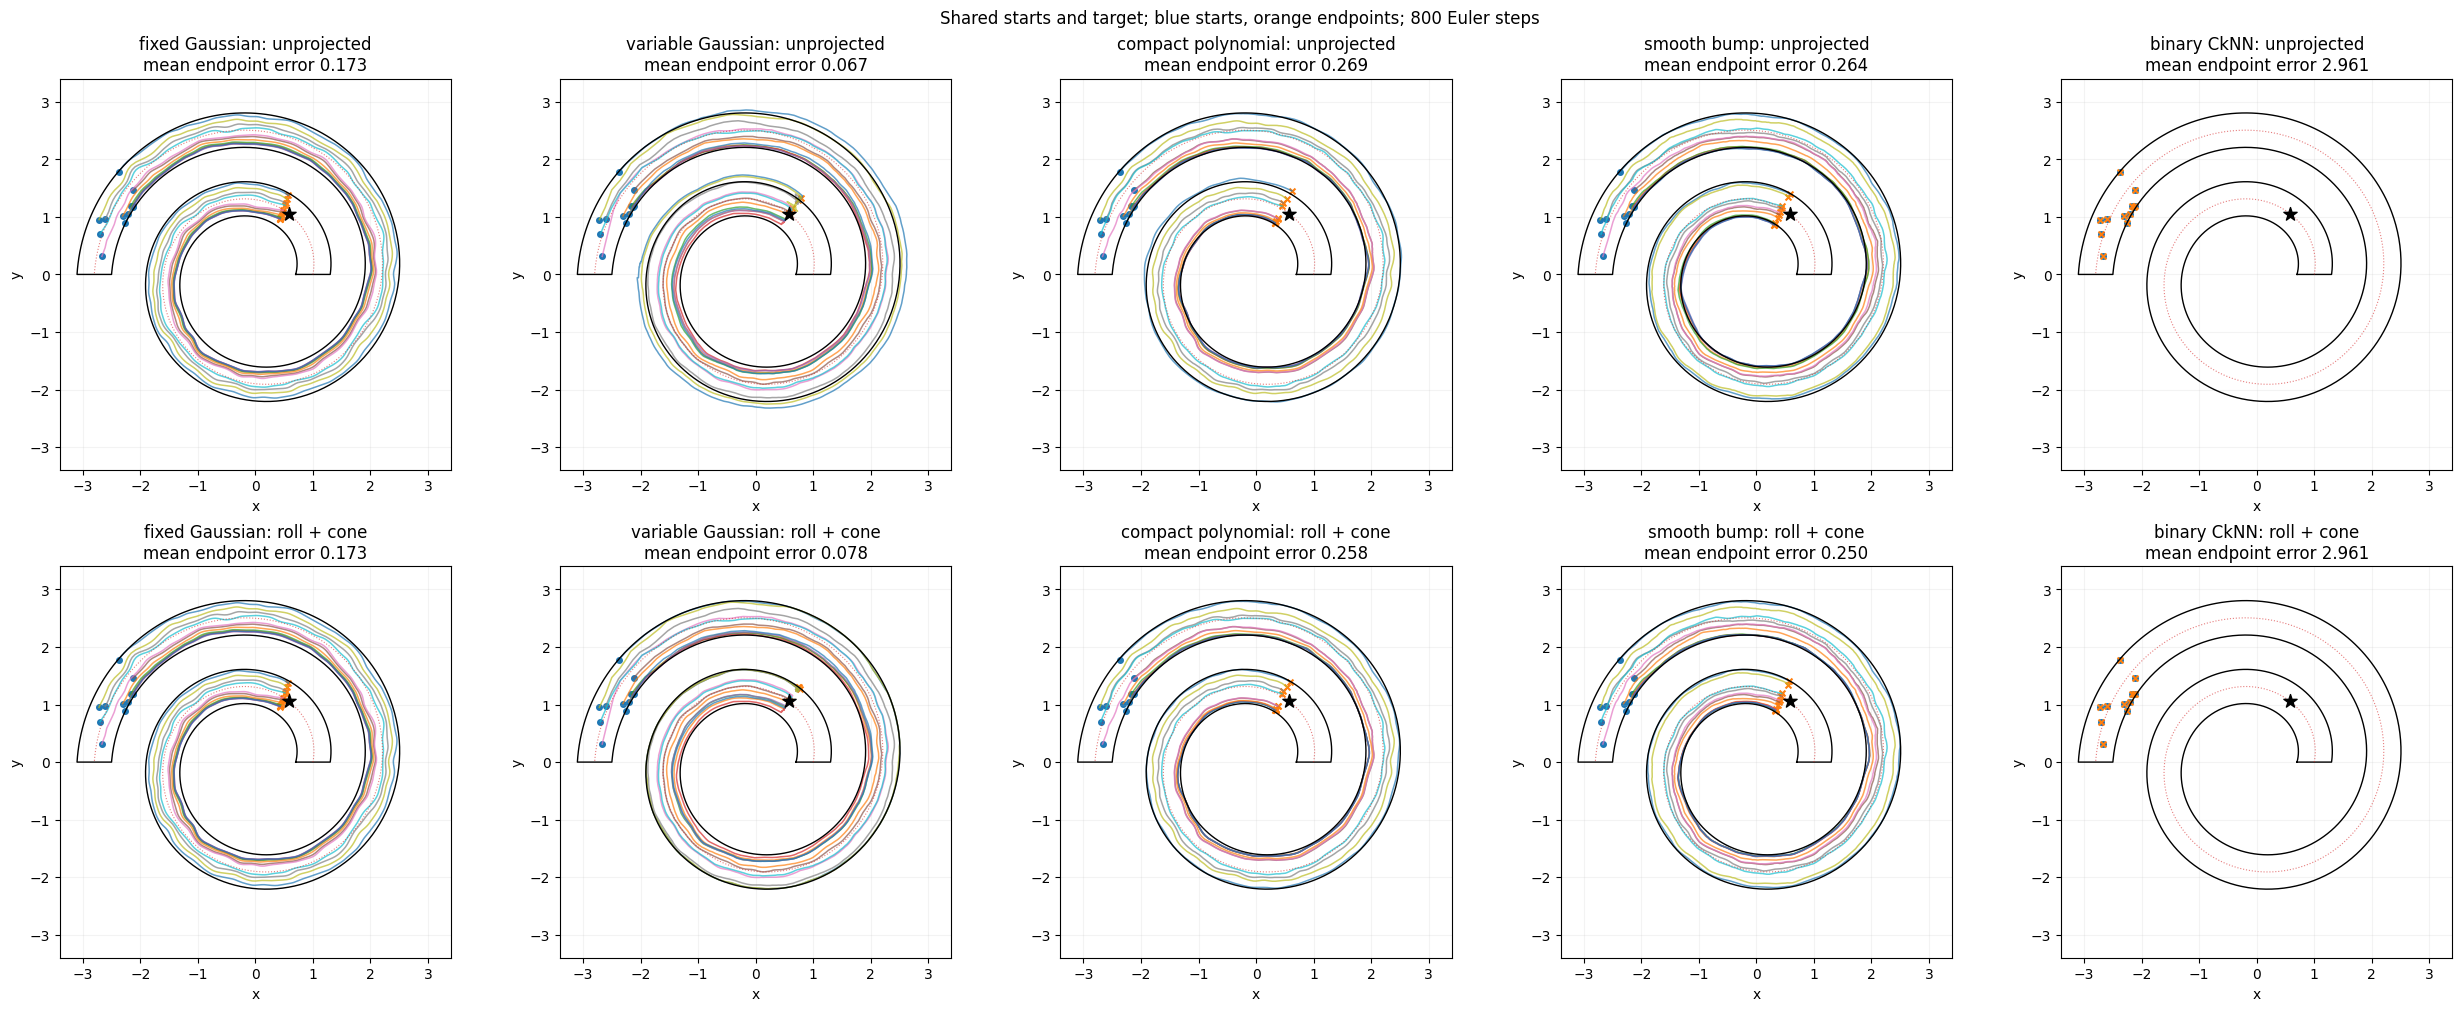

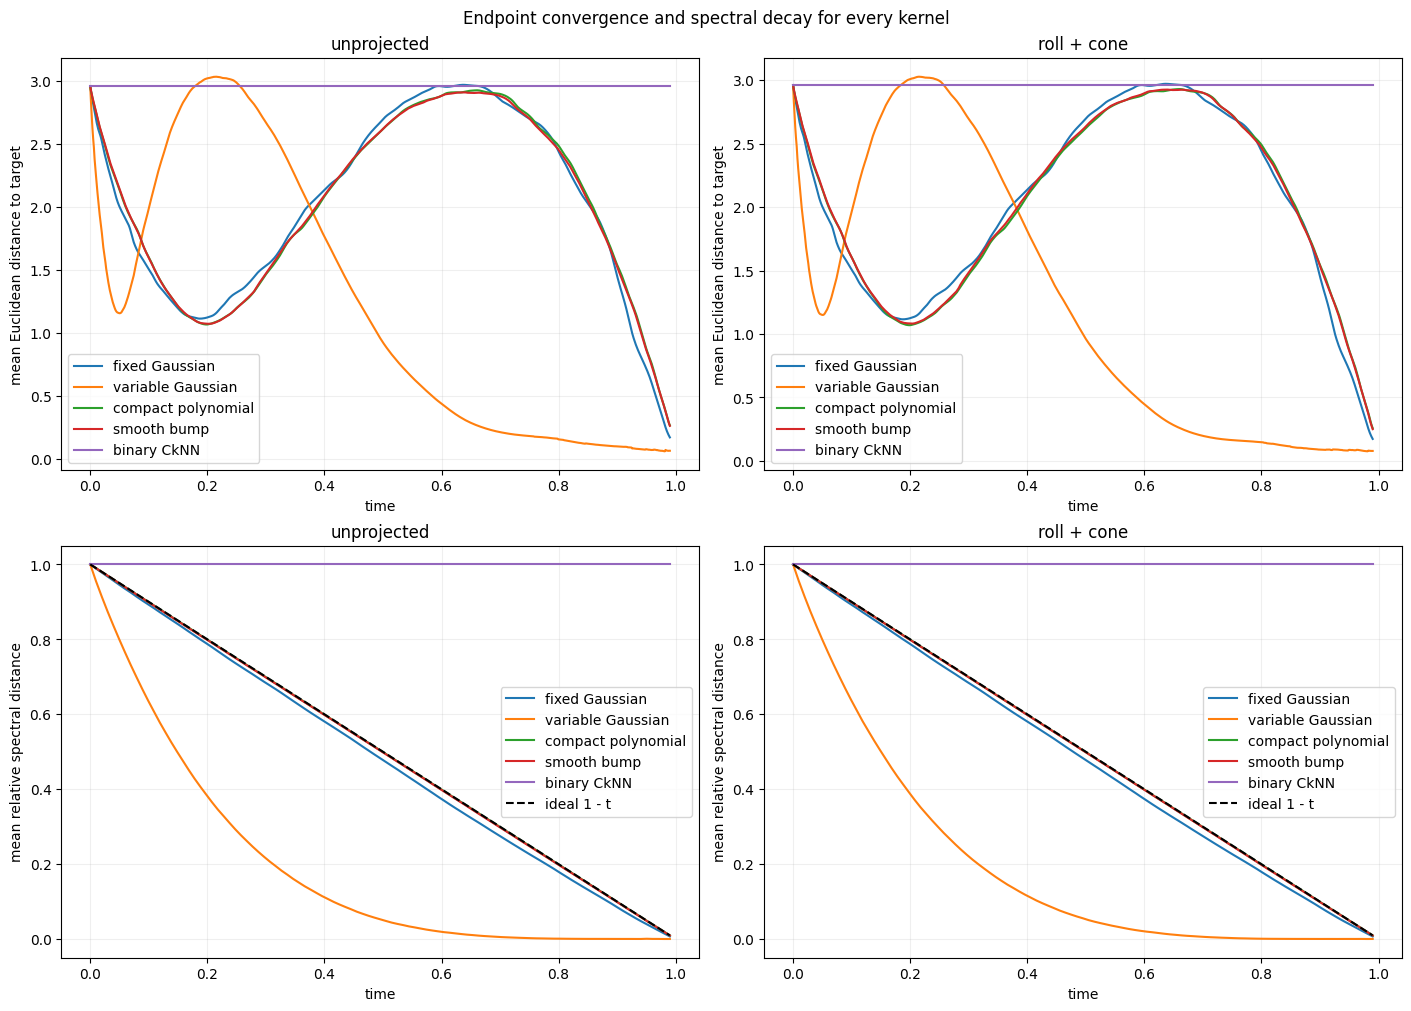

Lowest endpoint error passing domain/segment checks: variable Gaussian (0.0784).
Binary CkNN is a graph baseline: its almost-everywhere zero gradients leave the moving-point interpolation stationary.
Roll projection enforces the domain. Compare the raw boundary-field diagnostic and unprojected paths to assess the pre-metric itself.


In [9]:
plotting.plot_kernel_trajectories(
    roll, kernel_trajectories, kernel_starts, kernel_target, kernel_trajectory_df, kernel_integration_steps,
)
plotting.plot_kernel_convergence(kernel_trajectories, kernel_distance_traces, kernel_step_times, kernel_target)
kernels.report_best_guarded_kernel(kernel_trajectory_df, roll)

fixed Gaussian, 1600 guarded steps: mean endpoint error 0.1808; max segment gap penetration 0.0000


variable Gaussian, 1600 guarded steps: mean endpoint error 0.0523; max segment gap penetration 0.0000


compact polynomial, 1600 guarded steps: mean endpoint error 0.2627; max segment gap penetration 0.0000


smooth bump, 1600 guarded steps: mean endpoint error 0.2555; max segment gap penetration 0.0000


binary CkNN, 1600 guarded steps: mean endpoint error 2.9613; max segment gap penetration 0.0000


,coarse_mean_endpoint_error,refined_mean_endpoint_error,mean_endpoint_shift,refined_fraction_within_0.1,passes_domain_segment_checks,max_step_length,max_segment_gap_penetration,gap_crossing_segment_fraction,max_domain_violation,refinement_seconds
kernel,,,,,,,,,,
fixed Gaussian,0.172855,0.180778,0.045973,0.000000,True,0.117269,1.264124e-07,0.0,1.264124e-07,31.210146
variable Gaussian,0.078355,0.052297,0.031536,0.833333,True,0.417623,1.771744e-06,0.0,2.466687e-07,31.549633
compact polynomial,0.258450,0.262694,0.017869,0.000000,True,0.104687,2.152410e-07,0.0,2.152410e-07,31.351381
smooth bump,0.249779,0.255451,0.037467,0.000000,True,0.092348,1.953225e-07,0.0,1.953225e-07,31.856271
binary CkNN,2.961313,2.961313,0.000000,0.000000,True,0.000000,0.000000e+00,0.0,0.000000e+00,31.477262


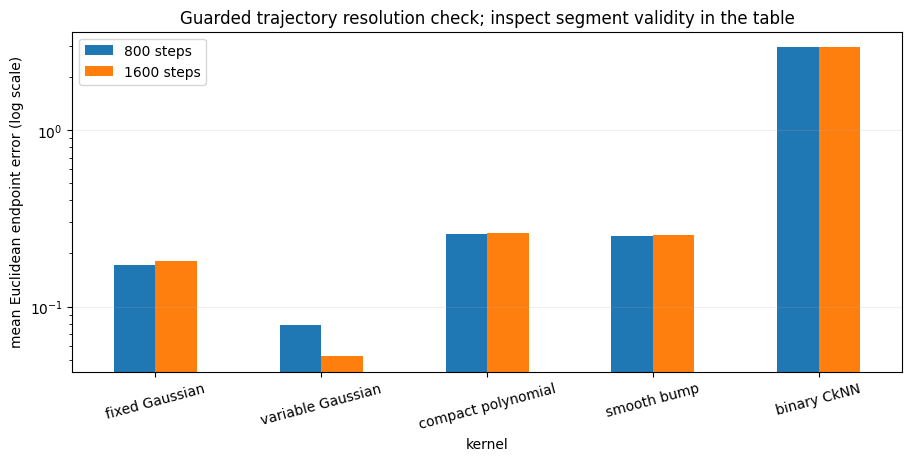

In [10]:
kernel_refinement_steps = 2 * kernel_integration_steps
kernel_refined_trajectories, kernel_refinement_df = kernels.refinement_check(
    kernel_models, roll, kernel_trajectories, kernel_starts, kernel_target, kernel_final_time,
    kernel_refinement_steps,
)
display(kernel_refinement_df)
plotting.plot_refinement_errors(kernel_refinement_df, kernel_integration_steps, kernel_refinement_steps)

The fields use a shared color scale and direction-normalized arrows. The two trajectory rows separate the raw field from a common roll projection and boundary-cone guard. Projection can keep a poor field inside the roll, so read endpoint errors together with the raw boundary diagnostic and unprojected paths. Unsupported queries are reported explicitly. The segment diagnostic samples nine points along each Euler segment and reports the largest distance outside the roll: projecting endpoints alone can still allow a step across a gap to the neighboring turn. A penetration tolerance of $10^{-3}$ accounts for small boundary chords and floating-point error.

**Saved-run observations.** With 5,000 construction points, 12 shared starts, and $t=0.99$, the guarded 1,600-step mean endpoint errors are about 0.181 (fixed Gaussian), 0.052 (variable Gaussian), 0.263 (compact polynomial), 0.256 (smooth bump), and 2.961 (binary CkNN). All guarded runs pass the segment check: no Euler segment crosses a gap to the neighboring turn (maximum gap penetration $\le 2\times10^{-6}$). On the roll, the variable Gaussian is again the only profile that gets most starts within 0.1 of the target (83% after refinement), and its largest step (0.42) stays below the 0.6 gap. The compact profiles take smaller steps (about 0.09–0.12) and change little under refinement (shifts of 0.02–0.05). However, they stop 0.25 short of the target on average, so their fields flatten out before reaching it. Unprojected, the smooth profiles leave the roll by at most 0.16 (variable Gaussian) and 0.005 (fixed Gaussian). The fixed Gaussian therefore needs the projection least. Binary CkNN remains stationary.

Raw spectral distances have different scales across profiles; the decay plot therefore normalizes each path by its own initial distance. Euclidean endpoint error compares target convergence in the common planar coordinates. These are deterministic toy comparisons on uniformly sampled construction points, not a density-robustness benchmark.

The fitted extensions, kernels, graphs, trajectories, and refinement results are available in kernel_models, kernel_fitted, kernel_graphs, kernel_trajectories, and kernel_refinement_df, indexed by the profile labels used in the plots.

## Train CellFlow RFM between the two Gaussian clouds

The outer-end Gaussian is the source/control distribution and the inner-end Gaussian is the target. The selected model from `kernel_models` supplies the same biharmonic geometry to OT matching and RFM interpolation:

$$c(x,y)=d_{\mathrm{BH}}(x,y)=\|\Psi(x)-\Psi(y)\|_2,\qquad \Psi_k(x)=\phi_k(x)/(\lambda_k+10^{-8}).$$

`match_biharmonic` evaluates the continuous Nyström embedding and calls the existing `cellflow.utils.match_linear` with the **unsquared** embedding distance. The standard `CellFlow(..., solver="otrfm") → prepare_data → prepare_model → train → predict` workflow keeps all cell coordinates two-dimensional and samples pairs from the OT coupling on each training batch. This is a linear OT problem with a manifold-aware cost.

Run the data-generation, construction, roll-helper, and kernel-fit cells above first. The kernel comparison plots are optional. The compact network and training settings below are the annulus notebook's. OT uses mean cost scaling, so `rfm_ot_epsilon` is relative to the batch's mean biharmonic cost. Training interpolation projects to the roll; standard model prediction is unconstrained, and the evaluation reports its domain violations. Evaluation uses the fitted clouds and measures reconstruction, not generalization.

With 32 interpolation steps, one training Euler step along the roughly 18-unit centerline is about 0.56 long, just below the 0.6 gap between turns. The training interpolations are projected to the nearest turn after every step.

In [11]:
rfm_kernel_name = "fixed Gaussian"
rfm_nystroem = kernel_models[rfm_kernel_name]
rfm_ot_epsilon = 0.05
rfm_batch_size = 32
rfm_interpolation_steps = 32
rfm_num_iterations = 300
rfm_seed = 2026
rfm_target_key, rfm_condition = "inner_gaussian", "inner Gaussian"

rfm_source = outer_gaussian_points.astype(np.float32)
rfm_target = inner_gaussian_points.astype(np.float32)
assert kernel_spectral_weight_type == "biharmonic"
assert np.all(roll.contains(rfm_source, tol=1e-6)) and np.all(roll.contains(rfm_target, tol=1e-6))  # float32 rounding

# Embed each batch once, then let OTT form its pairwise cost matrix.
# Euclidean distance in these weighted coordinates IS biharmonic distance.
rfm_embed = jax.jit(jax.vmap(rfm_nystroem.extend_point))
match_biharmonic = flows.make_entropic_match_fn(rfm_ot_epsilon, embed=rfm_embed)
rfm_match_jit = jax.jit(match_biharmonic)

print(f"Geometry: {rfm_kernel_name}, {rfm_nystroem.Psi.shape[1]} biharmonic modes")
print(f"Source: {rfm_source.shape}; target: {rfm_target.shape}")
print(f"Batch size: {rfm_batch_size}; interpolation steps: {rfm_interpolation_steps}")
print(f"OT cost: unsquared biharmonic distance; relative epsilon: {rfm_ot_epsilon}")

Geometry: fixed Gaussian, 32 biharmonic modes
Source: (250, 2); target: (250, 2)
Batch size: 32; interpolation steps: 32
OT cost: unsquared biharmonic distance; relative epsilon: 0.05


,coupling diagnostics
coupling_mass,9.999994e-01
max_source_marginal_error,4.190952e-09
max_target_marginal_error,6.984919e-09
OT_mean_biharmonic_cost,1.572021e+01
independent_mean_biharmonic_cost,1.572022e+01


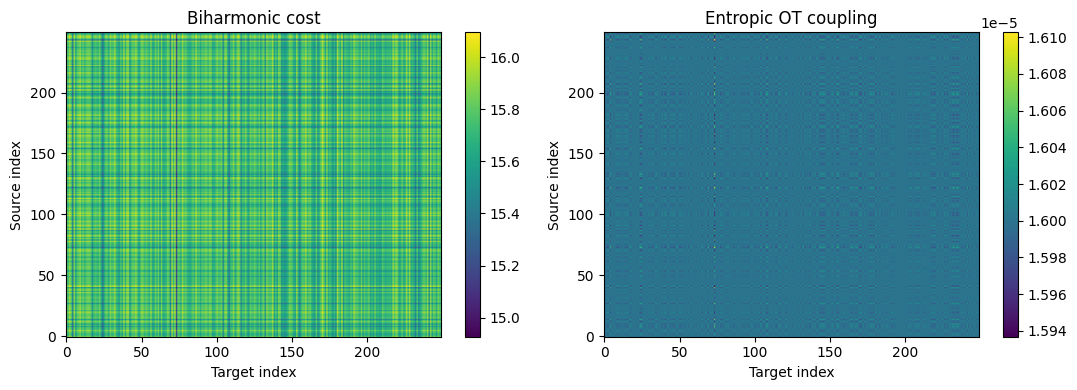

In [12]:
# Full-cloud diagnostic; training recomputes the coupling for each sampled batch.
rfm_cost_matrix = cdist(np.asarray(rfm_embed(jnp.asarray(rfm_source))), np.asarray(rfm_embed(jnp.asarray(rfm_target))))
rfm_coupling = np.asarray(rfm_match_jit(rfm_source, rfm_target))
flows.check_coupling(rfm_coupling, len(rfm_source), len(rfm_target))
flows.check_rectangular_batch(rfm_match_jit, rfm_source, rfm_target)

# The OT cost agrees with the distance used by RFM.
rfm_check_distances = rfm_nystroem.distance_grad_and_norm_batch(jnp.asarray(rfm_source[:8]), jnp.asarray(rfm_target[:8]))[0]
np.testing.assert_allclose(np.diag(rfm_cost_matrix[:8, :8]), np.asarray(rfm_check_distances), rtol=1e-5, atol=1e-6)

display(flows.coupling_diagnostics(rfm_coupling, rfm_cost_matrix, "biharmonic"))
plotting.plot_matrices([(rfm_cost_matrix, "Biharmonic cost"), (rfm_coupling, "Entropic OT coupling")])

In [13]:
# AnnData contains only the two Gaussian clouds; the uniform roll is geometry.
rfm_adata = flows.make_toy_adata(rfm_source, rfm_target, rfm_target_key)
rfm_cf = flows.prepare_toy_model(
    rfm_adata, "otrfm", rfm_target_key, **flows.DEFAULT_ARCHITECTURE,
    match_fn=match_biharmonic,
    nystroem=rfm_nystroem,
    optimizer=optax.adam(1e-3),
    solver_kwargs={
        "interpolation_steps": rfm_interpolation_steps,
        "projection_fn": project_to_roll,
        "project_to_manifold": False,
        "max_velocity_norm": 30.0,
    },
    seed=rfm_seed,
)


# The default dataloader must see the outer end as source and the inner end as target.
def is_outer(cells):
    return roll.roll_angle(cells) > 1.5 * np.pi


def is_inner(cells):
    return roll.roll_angle(cells) < 1.5 * np.pi


flows.check_source_target_split(rfm_cf, rfm_batch_size, rfm_seed, is_outer, is_inner)
print("Solver:", type(rfm_cf.solver).__name__)
print("Coordinate dimensions:", rfm_cf.train_data.cell_data.shape[1])
print("Conditions:", rfm_cf.train_data.condition_data)

[                                        ] | 0% Completed | 379.39 us

[########################################] | 100% Completed | 102.30 ms

[                                        ] | 0% Completed | 136.15 us

[########################################] | 100% Completed | 103.42 ms

[                                        ] | 0% Completed | 165.72 us

[########################################] | 100% Completed | 101.05 ms

Solver: OTRFlowMatching
Coordinate dimensions: 2
Conditions: {'transport': array([[[1.]]])}


In [14]:
# Baseline: leave the source cloud unchanged.
# These empirical distribution metrics do not assume pointwise correspondences.
rfm_baseline_metrics = flows.distribution_metrics(rfm_source, rfm_target, roll)
print("Unchanged-source baseline:", rfm_baseline_metrics, flush=True)

rfm_losses, rfm_training_seconds = flows.train_timed(rfm_cf, rfm_num_iterations, rfm_batch_size)
print(f"Training finished in {rfm_training_seconds:.1f}s", flush=True)
print(f"Mean loss, first 25: {rfm_losses[:25].mean():.5f}; last 25: {rfm_losses[-25:].mean():.5f}")

Unchanged-source baseline: {'energy_distance_squared': 5.208941722006151, 'mean_error_to_target': 3.0086069107055664, 'outside_roll_fraction': 0.0}


  0%|          | 0/300 [00:00<?, ?it/s]

  0%|          | 1/300 [00:06<32:26,  6.51s/it]

  1%|          | 2/300 [00:07<15:57,  3.21s/it]

  1%|          | 3/300 [00:08<10:40,  2.16s/it]

  1%|▏         | 4/300 [00:09<08:20,  1.69s/it]

... (297 outputs left out)

100%|██████████| 300/300 [04:41<00:00,  1.11it/s, loss=17.3]

100%|██████████| 300/300 [04:41<00:00,  1.06it/s, loss=17.3]

Training finished in 281.8s


Mean loss, first 25: 142.41021; last 25: 16.18339


[                                        ] | 0% Completed | 229.98 us

[########################################] | 100% Completed | 101.37 ms

[                                        ] | 0% Completed | 151.38 us

[########################################] | 100% Completed | 102.09 ms

,energy_distance_squared,mean_error_to_target,outside_roll_fraction
unchanged source,5.208942,3.008607,0.0
trained RFM prediction,0.783824,0.632101,0.0


Predictions use the standard unconstrained ODE solver; no endpoint projection is applied.


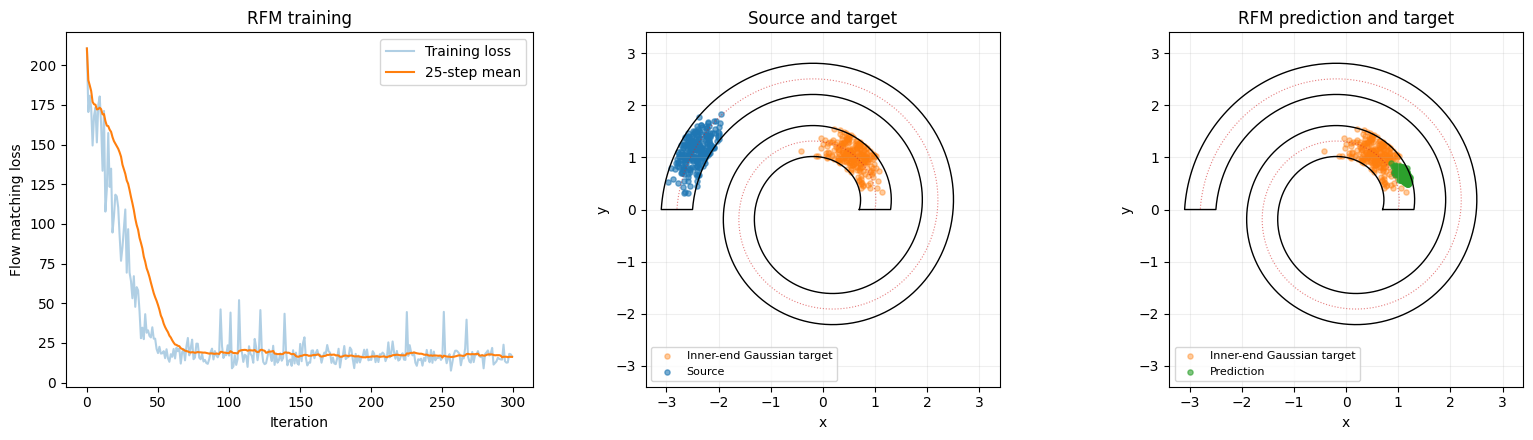

In [15]:
# Use the public prediction API on the outer-end/control cloud.
rfm_predicted = flows.predict_target(rfm_cf, rfm_adata, rfm_target_key, rfm_condition)
rfm_evaluation = pd.DataFrame(
    [rfm_baseline_metrics, flows.distribution_metrics(rfm_predicted, rfm_target, roll)],
    index=["unchanged source", "trained RFM prediction"],
)
display(rfm_evaluation)
print("Predictions use the standard unconstrained ODE solver; no endpoint projection is applied.")
plotting.plot_training_result(roll, rfm_losses, rfm_source, rfm_target, rfm_predicted,
                              target_label="Inner-end Gaussian target")

### Reading the training result

The coupling checks verify balanced marginals and agreement between the OT cost and the RFM biharmonic distance. The prediction table compares empirical distributions without assuming a pointwise pairing between the two clouds.

In the 300-iteration run above, squared energy distance decreased from 5.21 to 0.78 and mean-position error from 3.01 to 0.63. Unlike on the annulus, no predicted endpoint lies outside the roll, although `predict` integrates without projection. The coupling diagnostics also show that, with these settings, the entropic biharmonic coupling is practically the independent coupling: its transported cost (15.7202) equals the independent cost to five digits. Both clouds sit near opposite ends of one long strip, so every pair has a similar biharmonic distance, and the relative regularization $\varepsilon=0.05$ smooths out the small differences. The remaining endpoint error therefore comes from the field fit, not from the pairing. The kernel comparison shows that even the exact fixed-Gaussian RFM field stops about 0.18 from its target.

## Inspect the learned vector field at a point and time

Set `rfm_query_point` to the current position $x_t$ and `rfm_field_time` to a time in $[0,1]$, then rerun the cell below. It evaluates $v_\theta(t,x_t\mid\mathrm{inner\ Gaussian})$ using the trained inference weights, the same condition as prediction, and dropout disabled.

The colored arrows show the learned field on a grid restricted to the roll; the red arrow highlights the selected point. Colors encode speed. All arrow lengths equal `arrow_dt` times velocity, so their magnitudes remain comparable. These are instantaneous velocities. The plot uses the field directly, including any components pointing across a boundary.

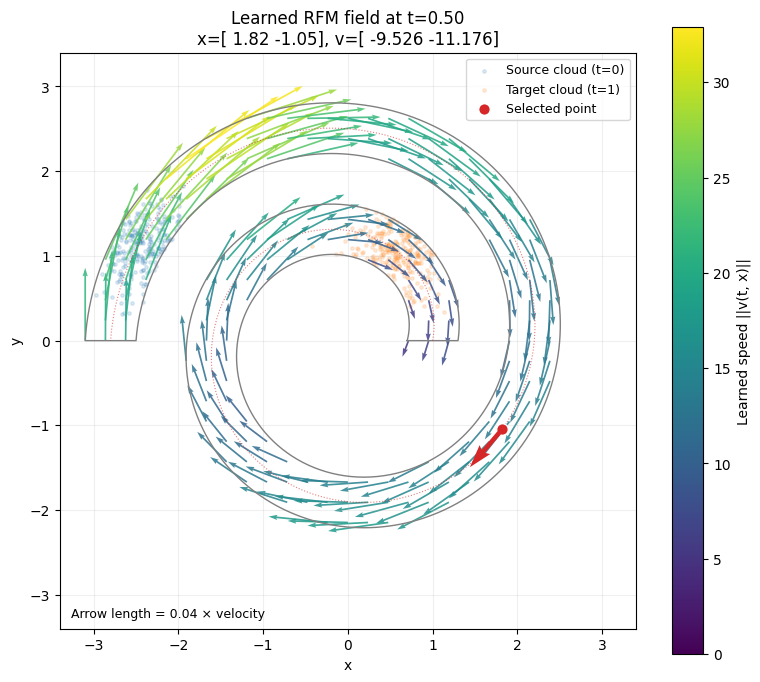

v(t=0.5, x=[1.8213211297988892, -1.0462087392807007]) = [ -9.525927 -11.176088]
Speed: 14.684966


In [16]:
# Change these two values and rerun this cell. Default: the centerline point halfway along the roll.
rfm_query_point = roll.strip_point(roll.theta_at_arc_length(0.5 * roll.centerline_length)).astype(np.float32)
rfm_field_time = 0.5

rfm_field_fig, rfm_field_ax, rfm_query_velocity = plotting.plot_learned_field(
    roll, rfm_cf, rfm_query_point, rfm_field_time, rfm_source, rfm_target,
)
print(f"v(t={rfm_field_time}, x={rfm_query_point.tolist()}) = {rfm_query_velocity}")
print(f"Speed: {np.linalg.norm(rfm_query_velocity):.6f}")

## Learned trajectories from new source samples

Draw fresh points from the same Gaussian as the source dataset, conditioned to lie on the outer half-turn of the roll. Change `rfm_n_new_points` or `rfm_trajectory_seed` below to choose a different sample. Each trajectory solves $\dot{x}_t=v_\theta(t,x_t\mid\mathrm{inner\ Gaussian})$ from $t=0$ to $t=1$ using the trained inference weights and the standard predictor's Tsit5 solver and tolerances. Saving intermediate states makes the full paths visible.

The circles mark starting points, crosses mark endpoints, and small arrows indicate travel direction. The offset plot shows the radial offset from the centerline of the nearest turn; a path leaves the roll when it exits the shaded band. The trajectories use the learned field directly, so boundary crossings are retained.

In [17]:
rfm_n_new_points = 6
rfm_trajectory_seed = 2027
rfm_trajectory_times = np.linspace(0.0, 1.0, 201, dtype=np.float32)

# Fresh draws from the source distribution, independent of the training cloud.
rfm_new_start_points = roll.sample_gaussian(
    mean_outer, variance, rfm_n_new_points, np.random.default_rng(rfm_trajectory_seed), theta_window=outer_window
)[0].astype(np.float32)
assert not np.any(np.all(rfm_new_start_points[:, None, :] == rfm_source[None, :, :], axis=2))

# Shape: (number of new points, number of saved times, 2). The endpoints are checked
# against standard prediction inside `integrate_learned_paths`.
rfm_new_trajectories, rfm_new_solver_steps = flows.integrate_learned_paths(
    rfm_cf, rfm_new_start_points, rfm_trajectory_times
)
print(f"Integrated {rfm_n_new_points} new source samples, with {len(rfm_trajectory_times)} saved times each.")

Integrated 6 new source samples, with 201 saved times each.


,start_x,start_y,end_x,end_y,min_sampled_centerline_offset,max_sampled_centerline_offset,endpoint_in_roll,all_saved_points_in_roll,adaptive_solver_steps
Path 1,-2.431977,1.117358,1.100436,0.648762,-0.259062,0.175701,True,True,1198
Path 2,-2.706498,0.496838,0.939196,0.746979,-0.252564,0.071706,True,True,1147
Path 3,-2.523677,0.877647,1.047995,0.669053,-0.278199,0.134837,True,True,1188
Path 4,-2.640233,0.828827,1.012070,0.726027,-0.224363,0.126704,True,True,1216
Path 5,-2.487459,1.175445,1.092437,0.689895,-0.215913,0.184466,True,True,1172
Path 6,-2.542616,1.322274,1.096626,0.750110,-0.134857,0.214053,True,True,1159


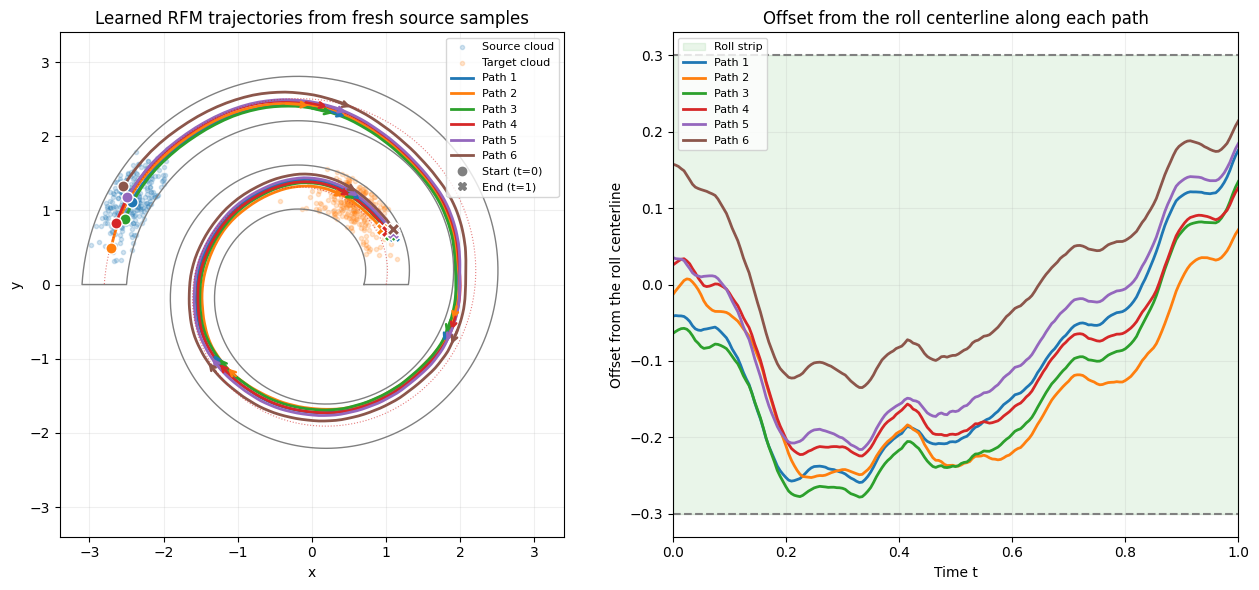

0/6 paths leave the roll at a saved time.


In [18]:
rfm_new_path_summary = flows.path_domain_summary(
    roll, rfm_new_start_points, rfm_new_trajectories, rfm_new_solver_steps
)
display(rfm_new_path_summary)
plotting.plot_learned_paths(roll, rfm_new_trajectories, rfm_trajectory_times, rfm_source, rfm_target)
print(f"{np.count_nonzero(~rfm_new_path_summary['all_saved_points_in_roll'])}/{rfm_n_new_points} "
      "paths leave the roll at a saved time.")

## Four-way comparison: Riemannian vs. Euclidean Flow Matching, biharmonic vs. Euclidean couplings

The RFM model above combines two geometry-aware ingredients: a **biharmonic OT coupling**, which decides which source and target points are paired, and **Riemannian interpolation**, which decides how each pair is connected. This section separates the two by training all four combinations on the same source and target clouds:

| | Biharmonic coupling $c_{\mathrm{BH}}(x,y)=\|\Psi(x)-\Psi(y)\|_2$ | Euclidean coupling $c_{\mathrm{E}}(x,y)=\|x-y\|_2$ |
| --- | --- | --- |
| **Riemannian FM** (`solver="otrfm"`) | `rfm_cf` (trained above) | `rfm_euclidean_cf` |
| **Euclidean FM** (`solver="otfm"`) | `fm_biharmonic_cf` | `fm_euclidean_cf` |

Both RFM models use the same Nyström geometry and the same `RFMInterpolation` settings as above: roll projection of the training interpolations, `interpolation_steps`, and velocity clipping. Both Euclidean models use the existing zero-noise constant-noise path
$$x_t=(1-t)x_0+tx_1,\qquad u_t=x_1-x_0,$$
whose straight segments ignore the roll. Every outer-to-inner chord leaves the roll and crosses the gaps between turns.

Everything else is shared. The network architecture and optimizer transformation are copied from `rfm_cf`. The time sampler, EMA, batch size, iteration count, and initialization seed also match. Both couplings are balanced and entropic, use unsquared costs, and share the relative `rfm_ot_epsilon` with mean cost scaling. Each coupling is recomputed on every training batch.

On the annulus, the two couplings could differ in *which way around the hole* a pair goes. The roll has only one route from the outer to the inner end, so the couplings can differ only in how they arrange points **across** the strip and **along** each end region. The coupling table therefore reports `same_side_mass`, the coupled mass whose two endpoints lie on the same side of the centerline, and `chord_leaves_roll_mass`, the coupled mass whose straight chord leaves the roll.

Run the RFM training, prediction, query-field, and fresh-sample trajectory cells above first. The extra RFM model costs about as much training time as the first because each step integrates the RFM interpolation. The Euclidean models train much faster. Training losses regress different velocity targets, so they are not comparable across interpolation types. Compare the endpoint distribution metrics, roll violations, and path geometry instead.

,coupling_mass,max_source_marginal_error,max_target_marginal_error,mean_biharmonic_cost,mean_euclidean_cost,same_side_mass,chord_leaves_roll_mass
coupling,,,,,,,
biharmonic,0.999999,4.190952e-09,6.984919e-09,15.720218,3.030904,0.500224,1.0
Euclidean,1.000000,4.656613e-09,7.916242e-09,15.720188,3.027942,0.508329,1.0
independent,1.000000,0.000000e+00,6.938894e-18,15.720218,3.030910,0.500224,1.0


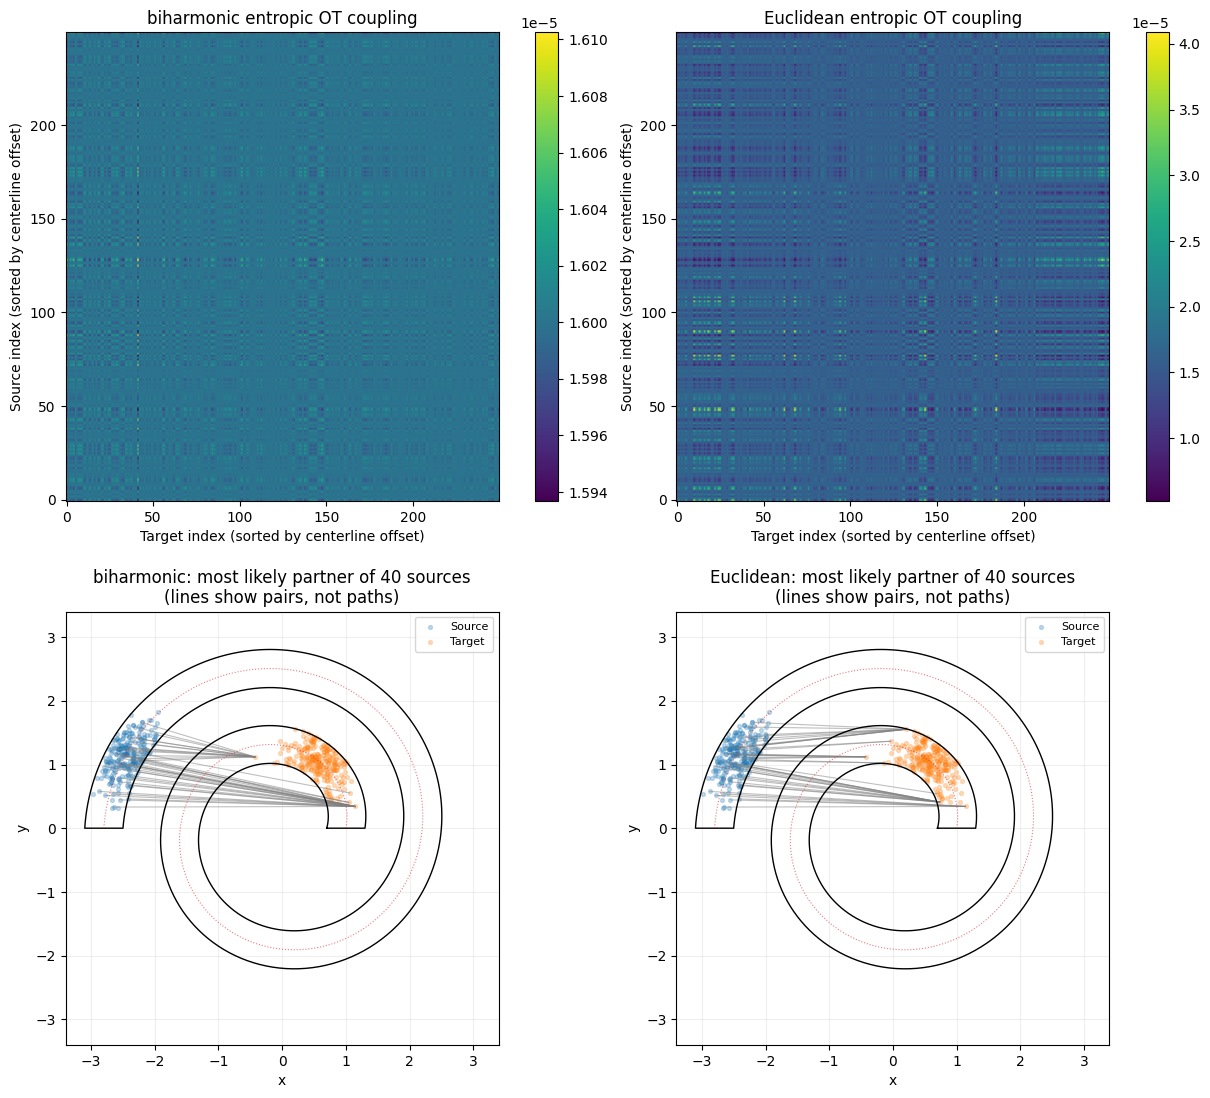

In [19]:
# Two entropic OT couplings with identical settings; only the ground cost differs.
cmp_ot_epsilon = rfm_ot_epsilon
cmp_batch_size = rfm_batch_size
cmp_num_iterations = rfm_num_iterations
cmp_seed = rfm_seed

match_euclidean = flows.make_entropic_match_fn(cmp_ot_epsilon)
cmp_match_euclidean_jit = jax.jit(match_euclidean)
flows.check_rectangular_batch(cmp_match_euclidean_jit, rfm_source, rfm_target)
cmp_cost_matrices = {"biharmonic": rfm_cost_matrix, "Euclidean": cdist(rfm_source, rfm_target)}
cmp_couplings = {
    "biharmonic": rfm_coupling,
    "Euclidean": np.asarray(cmp_match_euclidean_jit(rfm_source, rfm_target)),
}

# Pair-level diagnostics: does the straight chord leave the roll, and do the
# two endpoints lie on the same side of the centerline?
cmp_coupling_df = comparison.coupling_comparison_table(
    cmp_couplings, cmp_cost_matrices, rfm_source, rfm_target, pair_masks=roll.pair_masks(rfm_source, rfm_target)
)
display(cmp_coupling_df)
comparison.plot_coupling_comparison(roll, cmp_couplings, rfm_source, rfm_target, seed=cmp_seed,
                                    sort_by=roll.radial_coordinate, sort_label="centerline offset")

In [20]:
# Copy the fitted RFM model's architecture, optimizer transformation, time sampler, EMA and
# (for RFM) interpolation settings. Every new model initializes fresh parameters from the same seed.
cmp_architecture_kwargs = flows.copy_architecture_kwargs(rfm_cf)


def build_comparison_model(solver, match_fn):
    model = flows.build_matched_model(
        rfm_cf, rfm_adata, solver, match_fn, rfm_target_key, cmp_seed,
        nystroem=rfm_nystroem if solver == "otrfm" else None,
    )
    flows.check_source_target_split(model, cmp_batch_size, cmp_seed, is_outer, is_inner)
    return model


rfm_euclidean_cf = build_comparison_model("otrfm", match_euclidean)
fm_biharmonic_cf = build_comparison_model("otfm", match_biharmonic)
fm_euclidean_cf = build_comparison_model("otfm", match_euclidean)

cmp_models = {
    "RFM + biharmonic OT": rfm_cf,
    "RFM + Euclidean OT": rfm_euclidean_cf,
    "FM + biharmonic OT": fm_biharmonic_cf,
    "FM + Euclidean OT": fm_euclidean_cf,
}
cmp_colors = {
    "RFM + biharmonic OT": "tab:green",
    "RFM + Euclidean OT": "tab:cyan",
    "FM + biharmonic OT": "tab:purple",
    "FM + Euclidean OT": "tab:pink",
}
for name, model in cmp_models.items():
    print(f"{name}: {type(model.solver).__name__}")
print(f"Iterations: {cmp_num_iterations}; batch size: {cmp_batch_size}; seed: {cmp_seed}")
print(f"Unsquared OT costs; relative epsilon: {cmp_ot_epsilon}")

[                                        ] | 0% Completed | 153.43 us

[########################################] | 100% Completed | 101.07 ms

[                                        ] | 0% Completed | 132.44 us

[########################################] | 100% Completed | 101.48 ms

[                                        ] | 0% Completed | 154.18 us

[########################################] | 100% Completed | 101.55 ms

... (3 outputs left out)

[########################################] | 100% Completed | 101.93 ms

[                                        ] | 0% Completed | 236.11 us

[########################################] | 100% Completed | 101.31 ms

RFM + biharmonic OT: OTRFlowMatching
RFM + Euclidean OT: OTRFlowMatching
FM + biharmonic OT: OTFlowMatching
FM + Euclidean OT: OTFlowMatching
Iterations: 300; batch size: 32; seed: 2026
Unsquared OT costs; relative epsilon: 0.05


In [21]:
# The biharmonic RFM model is already trained; train the other three.
cmp_losses = {"RFM + biharmonic OT": rfm_losses}
cmp_training_seconds = {"RFM + biharmonic OT": rfm_training_seconds}
display(comparison.train_untrained(cmp_models, cmp_losses, cmp_training_seconds, cmp_num_iterations, cmp_batch_size))

Training RFM + Euclidean OT


  0%|          | 0/300 [00:00<?, ?it/s]

  0%|          | 1/300 [00:04<24:29,  4.91s/it]

  1%|          | 2/300 [00:05<12:38,  2.54s/it]

  1%|          | 3/300 [00:06<08:48,  1.78s/it]

  1%|▏         | 4/300 [00:07<07:02,  1.43s/it]

... (412 outputs left out)

 77%|███████▋  | 231/300 [00:00<00:00, 614.95it/s, loss=0.112]

100%|██████████| 300/300 [00:00<00:00, 537.49it/s, loss=0.112]

FM + Euclidean OT: 0.6s; mean loss first 25 1.39813, last 25 0.09950


,training_seconds,mean_loss_first_25,mean_loss_last_25
RFM + biharmonic OT,281.790170,142.410206,16.183387
RFM + Euclidean OT,264.871741,144.001247,15.987622
FM + biharmonic OT,11.344711,1.391981,0.104955
FM + Euclidean OT,0.559669,1.398132,0.099501


[                                        ] | 0% Completed | 128.34 us

[########################################] | 100% Completed | 101.66 ms

[                                        ] | 0% Completed | 146.35 us

[########################################] | 100% Completed | 101.86 ms

[                                        ] | 0% Completed | 168.74 us

[########################################] | 100% Completed | 101.68 ms

... (7 outputs left out)

[########################################] | 100% Completed | 103.04 ms

[                                        ] | 0% Completed | 210.23 us

[########################################] | 100% Completed | 101.36 ms

,energy_distance_squared,mean_error_to_target,outside_roll_fraction,between_turns_fraction,beyond_outer_fraction,not_on_inner_turn_fraction,mean_roll_violation,p95_roll_violation
unchanged source,5.208942,3.008607,0.000,0.000,0.0,1.0,0.000000,0.000000
RFM + biharmonic OT,0.783824,0.632101,0.000,0.000,0.0,0.0,0.000000,0.000000
RFM + Euclidean OT,0.708504,0.590593,0.008,0.008,0.0,0.0,0.000063,0.000000
FM + biharmonic OT,0.015752,0.060706,0.144,0.144,0.0,0.0,0.009018,0.063913
FM + Euclidean OT,0.018559,0.071540,0.132,0.132,0.0,0.0,0.008905,0.059082


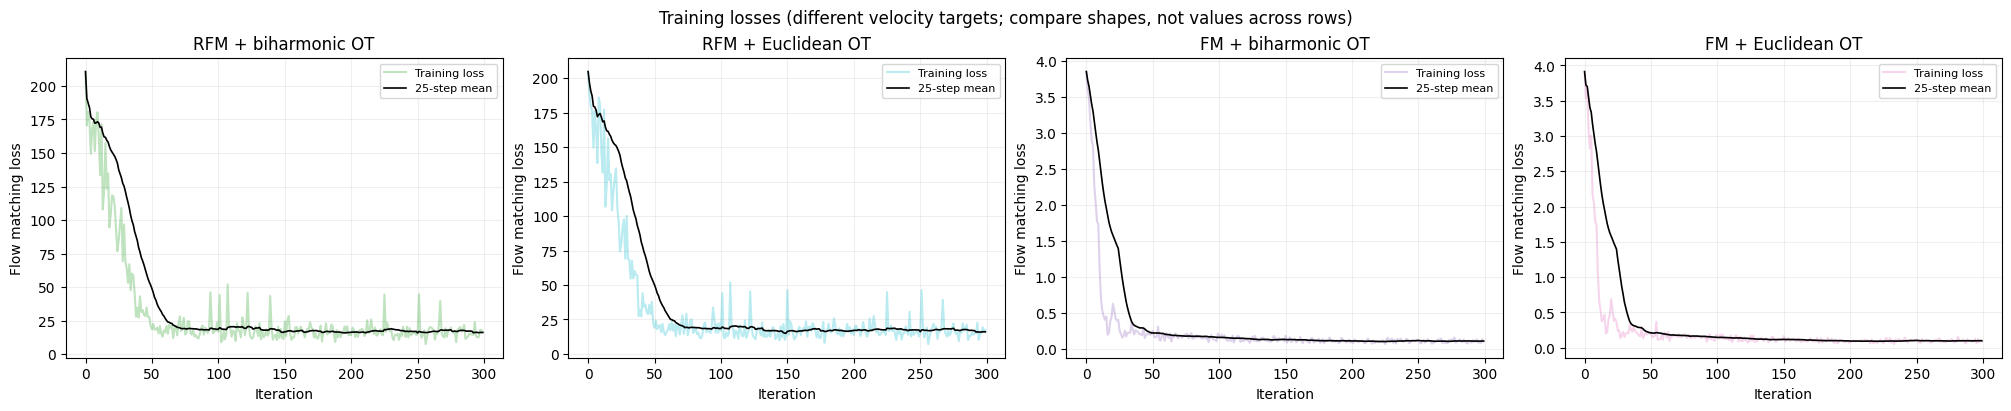

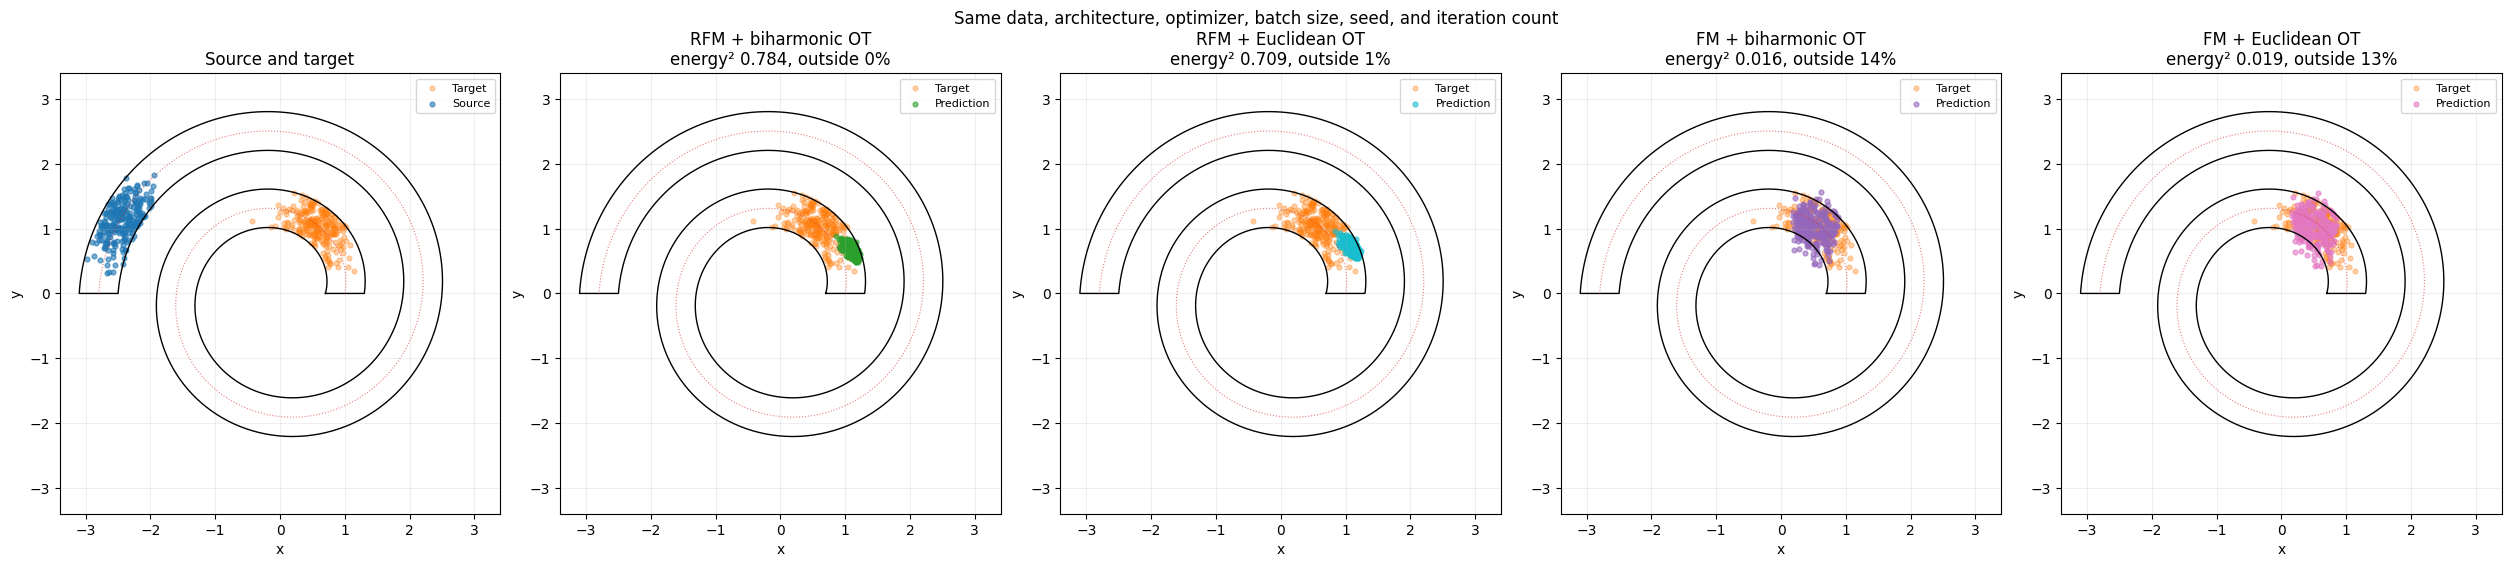

All predictions use standard unconstrained ODE integration; no endpoint projection is applied.


In [22]:
# The public prediction API and target condition match the RFM evaluation.
cmp_predicted = {
    name: flows.predict_target(model, rfm_adata, rfm_target_key, rfm_condition) for name, model in cmp_models.items()
}
np.testing.assert_allclose(cmp_predicted["RFM + biharmonic OT"], rfm_predicted, rtol=1e-4, atol=1e-4)
cmp_endpoint_metrics = comparison.endpoint_table(cmp_predicted, rfm_source, rfm_target, roll)
display(cmp_endpoint_metrics)

plotting.plot_loss_panels(
    cmp_losses, cmp_colors, "Training losses (different velocity targets; compare shapes, not values across rows)"
)
plotting.plot_prediction_panels(roll, rfm_source, rfm_target, cmp_predicted, cmp_colors, metrics=cmp_endpoint_metrics)
print("All predictions use standard unconstrained ODE integration; no endpoint projection is applied.")

### Compare the learned fields and fresh-sample paths

All four learned fields below use the same query point and time as the single-model field plot above (`rfm_query_point`, `rfm_field_time`). They also share the roll grid, arrow scale, and speed color scale. Arrow length is `cmp_arrow_dt` times velocity, so magnitudes are comparable across panels.

The path comparison reuses `rfm_new_start_points` and `rfm_trajectory_times` exactly. Every model integrates its own learned field with the same Tsit5 solver and tolerances as the public `predict` method, with no roll projection. The biharmonic RFM paths are recomputed and checked against `rfm_new_trajectories`. Segment-level gap penetration samples each straight segment between saved times, so it also detects chords that cut across a gap between two saved times. `paths_skipping_a_turn` counts paths whose nearest turn changes abruptly (the roll angle jumps by more than $\pi$ between saved times): such a path can stay on the roll at every saved time and still take a shortcut to another turn.

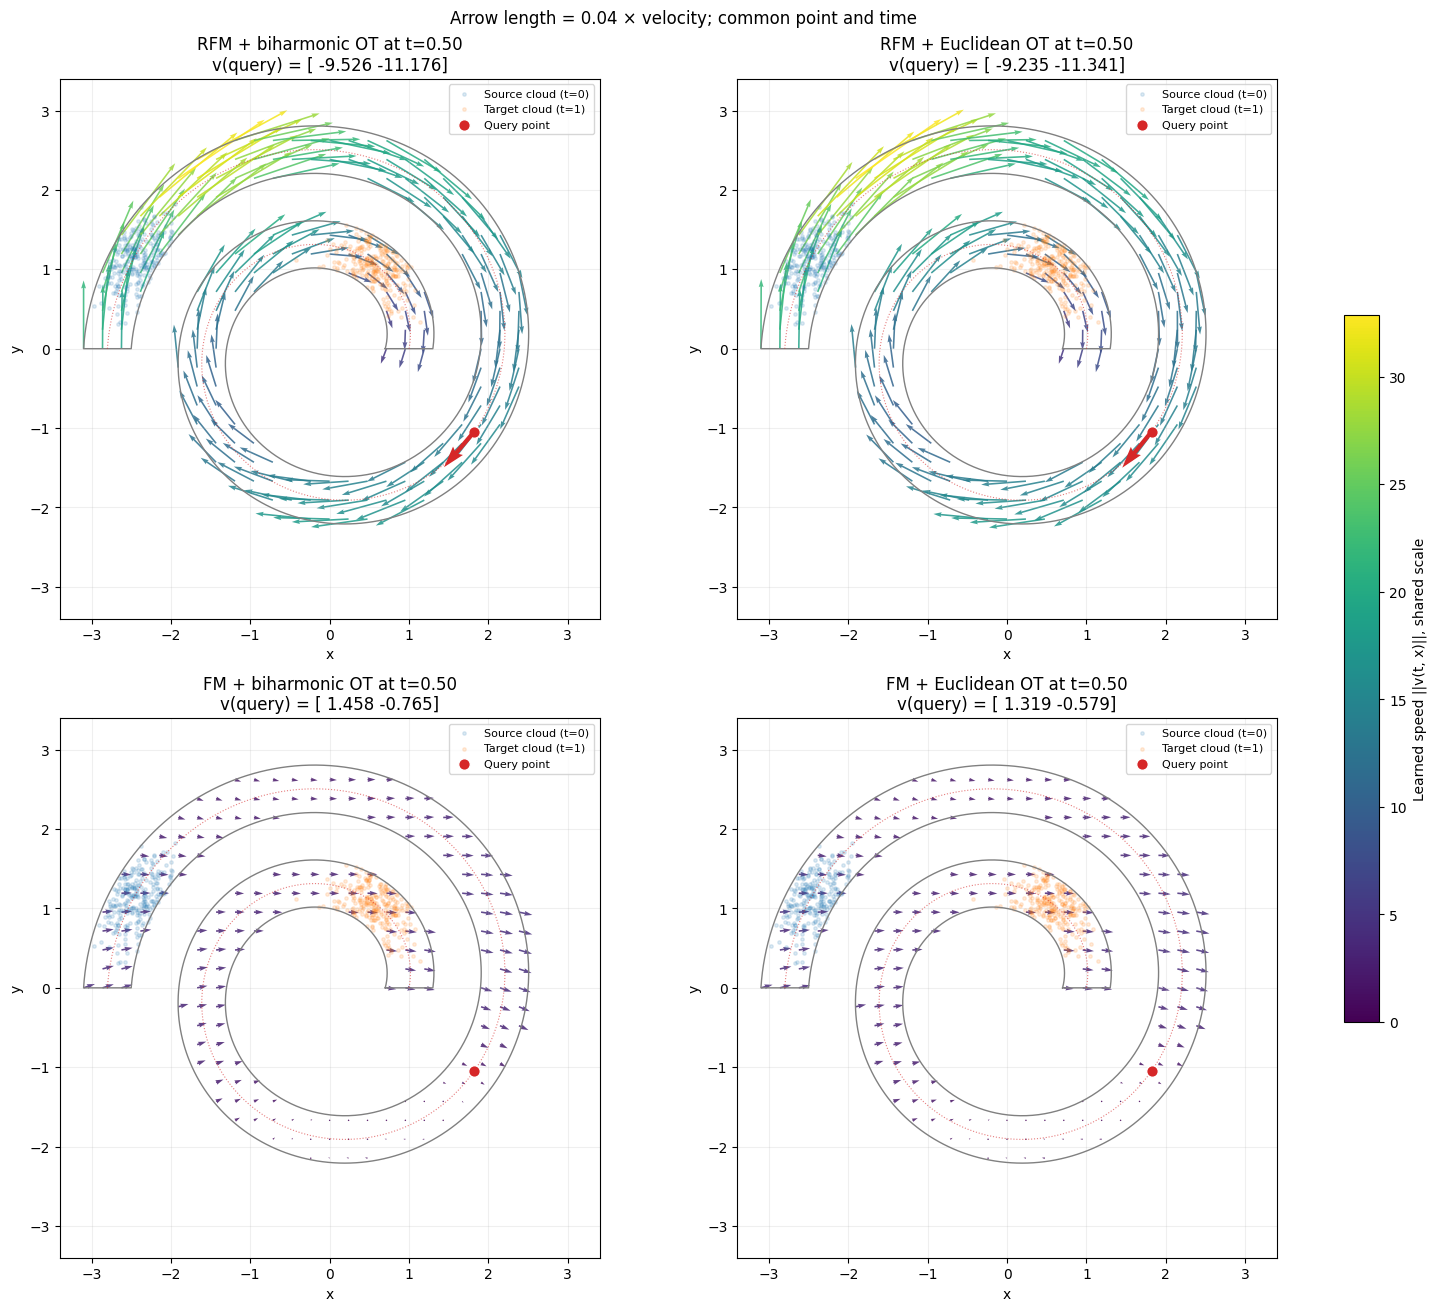

,query_vx,query_vy,query_speed
RFM + biharmonic OT,-9.525927,-11.176088,14.684966
RFM + Euclidean OT,-9.235273,-11.341055,14.625655
FM + biharmonic OT,1.457891,-0.764527,1.646191
FM + Euclidean OT,1.318855,-0.579016,1.440360


In [23]:
cmp_query_point = np.asarray(rfm_query_point, dtype=np.float32)
cmp_field_time = rfm_field_time
cmp_arrow_dt = 0.04

cmp_fields = plotting.plot_field_comparison(
    roll, cmp_models, cmp_query_point, cmp_field_time, rfm_source, rfm_target, arrow_dt=cmp_arrow_dt
)
display(pd.DataFrame(
    [values[-1] for values in cmp_fields.values()], index=list(cmp_fields), columns=["query_vx", "query_vy"],
).assign(query_speed=lambda df: np.hypot(df["query_vx"], df["query_vy"])))

In [24]:
# Reuse the same fresh source points and saved times as the RFM section above.
cmp_new_start_points = rfm_new_start_points.copy()
cmp_trajectory_times = rfm_trajectory_times.copy()

cmp_trajectories, cmp_solver_steps = comparison.integrate_all_paths(cmp_models, cmp_new_start_points, cmp_trajectory_times)
np.testing.assert_allclose(cmp_trajectories["RFM + biharmonic OT"], rfm_new_trajectories, rtol=1e-4, atol=1e-4)
print(f"Integrated {len(cmp_new_start_points)} shared fresh source samples "
      f"at {len(cmp_trajectory_times)} saved times for each of {len(cmp_models)} models.")

Integrated 6 shared fresh source samples at 201 saved times for each of 4 models.


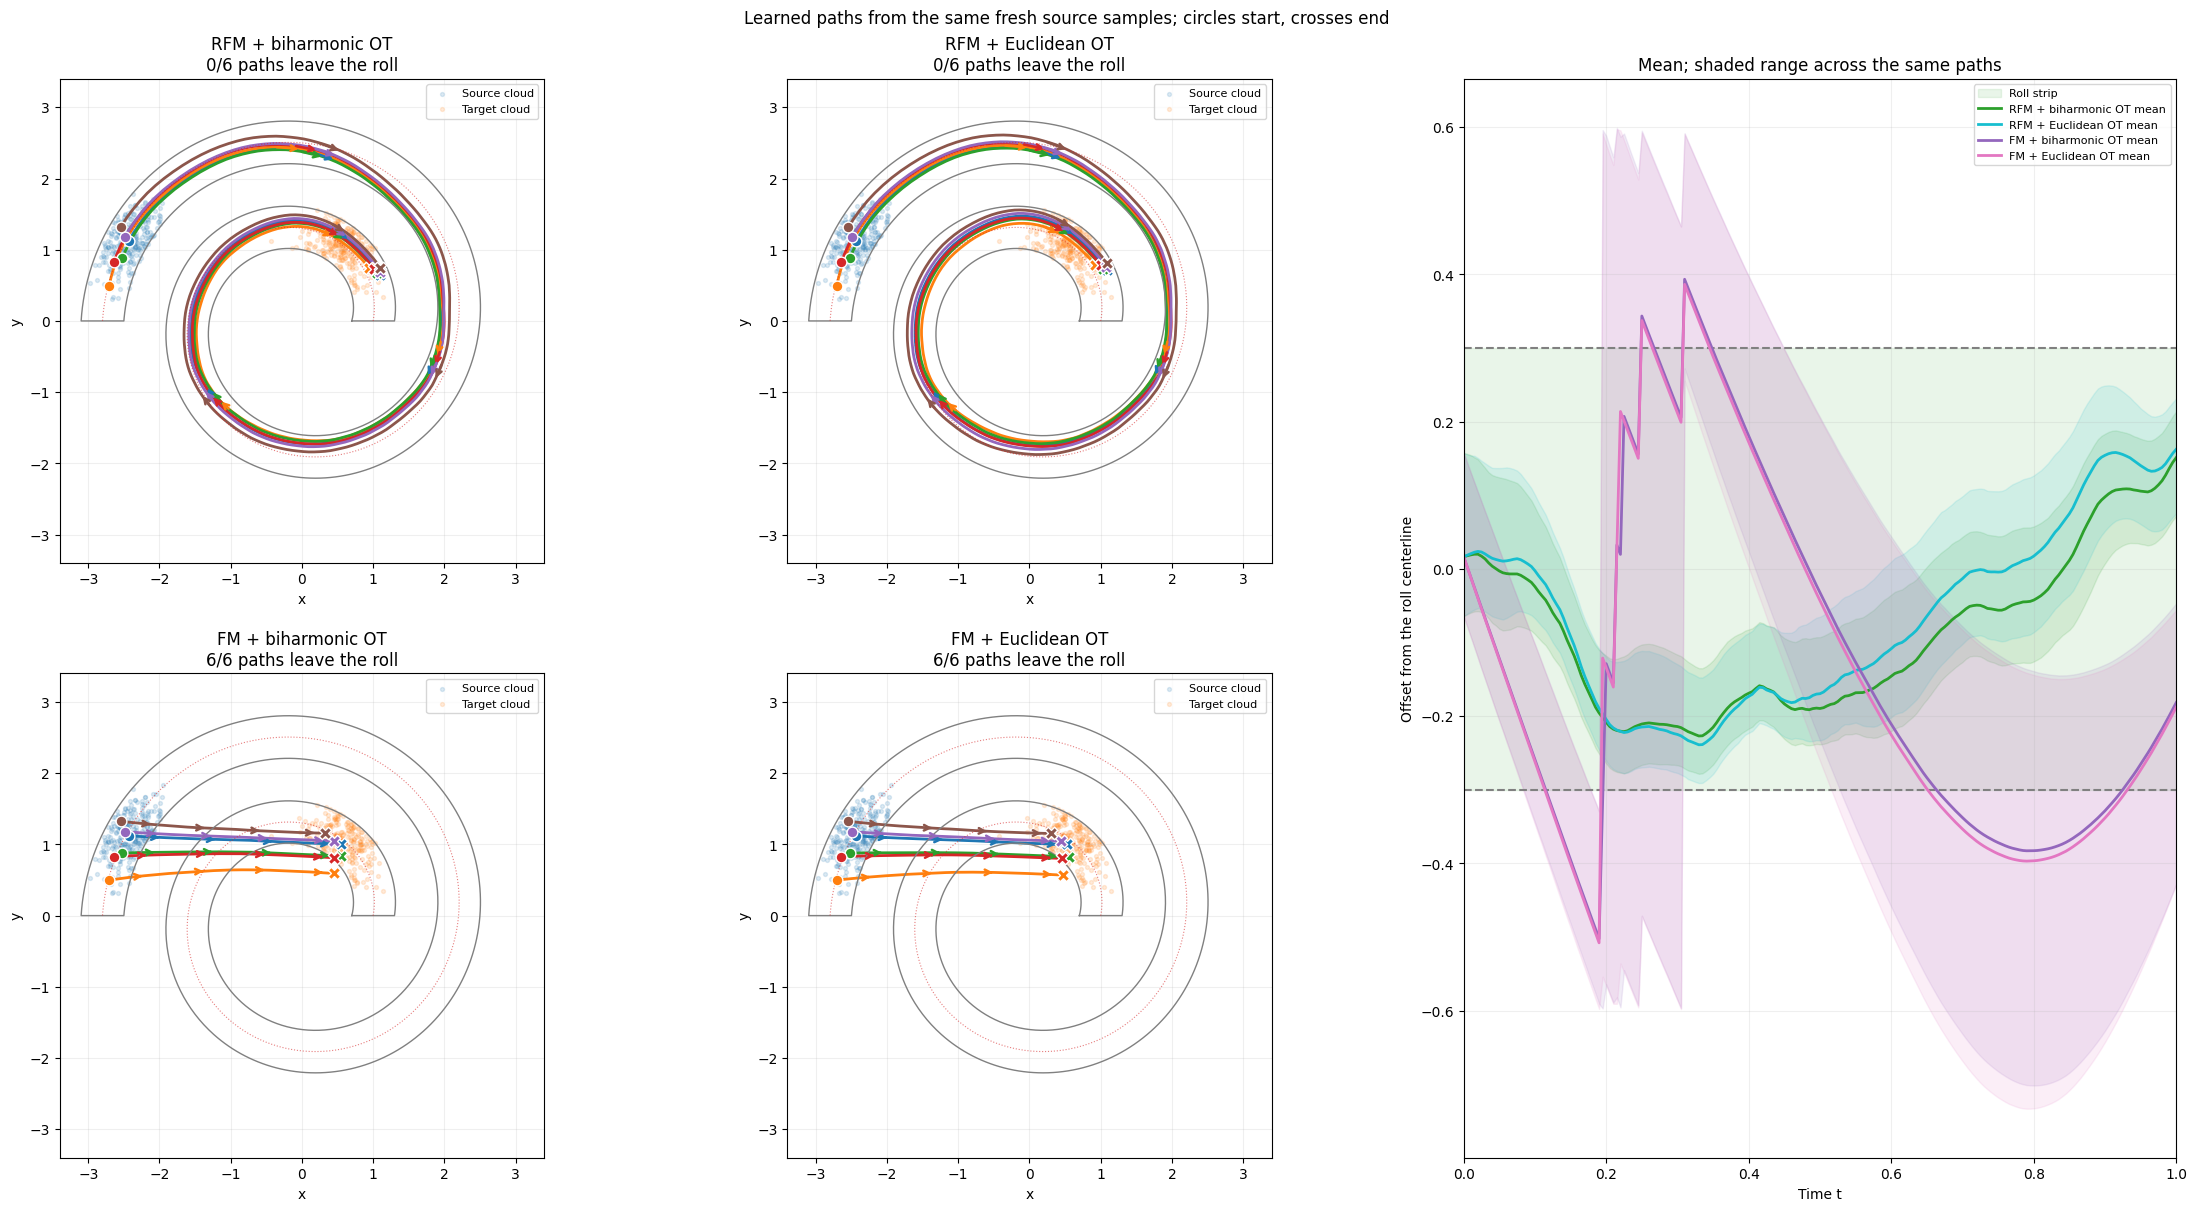

,paths_leaving_roll,endpoints_in_roll,fraction_saved_points_in_roll,paths_skipping_a_turn,min_sampled_offset,max_sampled_offset,mean_path_length,max_step_length,max_segment_gap_penetration,gap_crossing_segment_fraction,max_roll_violation,mean_adaptive_solver_steps
model,,,,,,,,,,,,
RFM + biharmonic OT,0,1.000000,1.000000,0,-0.278199,0.214053,15.746338,0.158848,0.000000,0.000000,0.000000,1180.000000
RFM + Euclidean OT,0,1.000000,1.000000,0,-0.290802,0.249374,15.922101,0.161756,0.000000,0.000000,0.000000,1188.166667
FM + biharmonic OT,6,0.833333,0.564677,6,-0.701544,0.599061,3.020625,0.016997,0.401544,0.442500,0.401544,531.000000
FM + Euclidean OT,6,0.833333,0.561360,6,-0.733001,0.597289,3.017550,0.017025,0.433028,0.446667,0.433001,545.166667


In [25]:
cmp_path_metrics = comparison.path_table(roll, cmp_trajectories, cmp_solver_steps)
plotting.plot_path_comparison(
    roll, cmp_trajectories, cmp_trajectory_times, rfm_source, rfm_target, cmp_colors, path_metrics=cmp_path_metrics
)
display(cmp_path_metrics)

energy_distance_squared  mean_error_to_target  \
interpolation coupling                                                       
RFM           biharmonic OT                 0.783824              0.632101   
              Euclidean OT                  0.708504              0.590593   
FM            biharmonic OT                 0.015752              0.060706   
              Euclidean OT                  0.018559              0.071540   

                             outside_roll_fraction  between_turns_fraction  \
interpolation coupling                                                       
RFM           biharmonic OT                  0.000                   0.000   
              Euclidean OT                   0.008                   0.008   
FM            biharmonic OT                  0.144                   0.144   
              Euclidean OT                   0.132                   0.132   

                             mean_roll_violation  paths_leaving_roll  \
interpolation coupling                                                 
RFM           biharmonic OT             0.000000                   0   
              Euclidean OT              0.000063                   0   
FM            biharmonic OT             0.009018                   6   
              Euclidean OT              0.008905                   6   

                             paths_skipping_a_turn  \
interpolation coupling                               
RFM           biharmonic OT                      0   
              Euclidean OT                       0   
FM            biharmonic OT                      6   
              Euclidean OT                       6   

                             max_segment_gap_penetration  mean_path_length  \
interpolation coupling                                                       
RFM           biharmonic OT                     0.000000         15.746338   
              Euclidean OT                      0.000000         15.922101   
FM            biharmonic OT                     0.401544          3.020625   
              Euclidean OT                      0.433028          3.017550   

                             training_seconds  
interpolation coupling                         
RFM           biharmonic OT        281.790170  
              Euclidean OT         264.871741  
FM            biharmonic OT         11.344711  
              Euclidean OT           0.559669

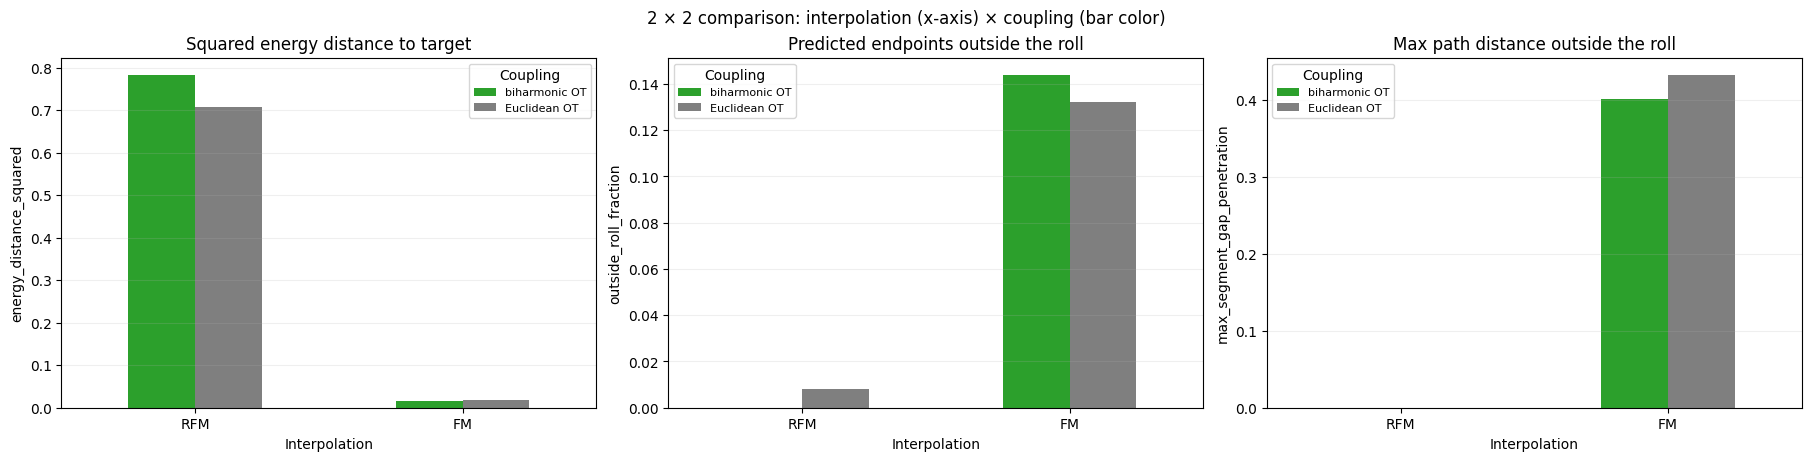

In [26]:
# One table per model: endpoint distribution metrics on the fitted source cloud,
# path geometry on the shared fresh samples, and training cost.
cmp_summary = comparison.factor_summary(
    cmp_endpoint_metrics, cmp_path_metrics, cmp_training_seconds, cmp_models,
    endpoint_columns=["energy_distance_squared", "mean_error_to_target", "outside_roll_fraction",
                      "between_turns_fraction", "mean_roll_violation"],
    path_columns=["paths_leaving_roll", "paths_skipping_a_turn", "max_segment_gap_penetration", "mean_path_length"],
)
display(cmp_summary)
comparison.plot_factor_bars(cmp_summary, [
    ("energy_distance_squared", "Squared energy distance to target"),
    ("outside_roll_fraction", "Predicted endpoints outside the roll"),
    ("max_segment_gap_penetration", "Max path distance outside the roll"),
])

### Reading the four-way comparison

Read the 2 × 2 table one factor at a time:

- **Coupling effect at fixed interpolation:** compare the two RFM rows with each other, then the two FM rows. Both couplings pair outer-end points with inner-end points. The coupling table shows whether the biharmonic cost changes that pairing, through `same_side_mass` and the biharmonic cost transported. `chord_leaves_roll_mass` shows how much coupled mass a straight Euclidean path would carry out of the roll.
- **Interpolation effect at fixed coupling:** compare RFM against FM within each coupling column. The Euclidean models regress straight-line targets, and every outer-to-inner chord leaves the roll. The RFM targets follow the roll during training, and their training interpolations are projected onto it.
- **Interaction:** a biharmonic coupling alone does not keep straight-line FM paths on the roll. Euclidean pairs can still be transported along geometry-aware RFM paths. The diagonal cells show whether the two ingredients help independently or only together.

All four `predict` calls integrate the learned field without projection. Endpoint violations therefore measure how well each learned field respects the domain, not a constraint enforced at inference. Metrics use the fitted clouds and the same six fresh samples. They describe this deterministic toy run, not generalization, so check them again whenever the kernel, OT regularization, interpolation resolution, or training length changes.

**Saved-run observations.** The two factors behave very differently on the roll:

- **Coupling barely matters.** Both couplings are close to independent (`same_side_mass` 0.50 and 0.51; the biharmonic and Euclidean transported costs equal the independent ones to three digits). The two RFM rows and the two FM rows are nearly identical.
- **Interpolation decides everything, in opposite directions for distribution and geometry.** FM matches the target distribution far better: squared energy distance 0.016–0.019 vs. 0.71–0.78 for RFM. However, its paths do not follow the roll. All six fresh FM paths leave the roll and jump across at least one turn: they cut straight through the gaps (maximum gap penetration 0.40–0.43, about 44% of segments cross a gap), with a mean length of 3.0. 13–14% of the FM endpoints land in a gap between turns. The RFM paths follow the strip all the way (mean length 15.7–15.9, the arc length between the clouds). No RFM path leaves the roll, and at most 0.8% of RFM endpoints lie outside it, all without projection at prediction time.
- **Cost:** with 32 interpolation steps, an RFM run takes about 270 s, against under 12 s for FM.

On this domain, RFM thus trades endpoint accuracy for paths that respect the geometry, while FM reaches the right distribution by tunnelling through the gaps.

## Conditional reference paths vs. exact geodesics

Every model above regresses a *conditional* reference field $u_t(x\mid x_0,x_1)$, evaluated along a reference path from $x_0$ to $x_1$. This section looks at those reference paths alone, without any network. It asks how close they come to the true shortest paths in the roll.

| Reference path | Construction |
| --- | --- |
| FM | $x_t=(1-t)x_0+tx_1$, the straight-line target $u_t=x_1-x_0$ of both FM models |
| RFM, training | `RFMInterpolation` on the fixed grid $t_k=k/K$ with $K$ = `interpolation_steps` Euler steps. It uses the training settings of `rfm_cf`: roll projection after every step and velocity clipping. These are the states and targets RFM training regresses |
| RFM, fine | The same field and projection with many more Euler steps. This separates the field itself from its discretization |

**Geodesics in the roll.** The roll carries the flat Euclidean metric and is simply connected. The shortest path between two of its points is therefore the *taut string*: it is straight wherever it is free, and it wraps along the inner (concave) edge of each turn. Unlike on the annulus, there is no closed form. In strip coordinates (roll angle $\theta$, radial offset $s$ from the centerline), however, the roll is the box $|s|\le w$, and the taut string advances monotonically in $\theta$. `SwissRoll.geodesic` fixes a uniform $\theta$ grid of 1,025 points between the endpoints and minimizes the polyline length over the offsets with box-constrained L-BFGS-B, starting from coarser grids. Refining the grid to 4,097 points changes the length by less than $2\times10^{-6}$. An unrestricted Dijkstra shortest path on a 60,000-point graph inside the roll is longer by only its zig-zag overhead (0.4%). The geodesic is returned at constant speed: $\gamma(t)$ is the point at arc length $tL$.

**Distances between a reference path $c$ and its geodesic $\gamma$.** Each distance answers a different question:

| Metric | Definition | What it measures |
| --- | --- | --- |
| Hausdorff | $\max\{\sup_{p\in c}d(p,\gamma),\ \sup_{q\in\gamma}d(q,c)\}$ | worst local deviation; one shortcut across a gap is enough to make it large |
| Chamfer | $\tfrac12\big(\overline{d(p,\gamma)}_{p\in c}+\overline{d(q,c)}_{q\in\gamma}\big)$, means over arc length | typical deviation along the whole curve |
| Wasserstein (time) | $W_2\big(\mathrm{law}(x_t),\mathrm{law}(\gamma(t))\big)$, $t\sim U[0,1]$ | where the path spends its time, so the speed profile counts too, not just the shape. This is the quantity closest to what flow matching transports |
| Wasserstein (arc) | $W_2$ between the uniform arc-length measures of $c$ and $\gamma$ | shape with mass matching: a path that covers only part of $\gamma$ is penalized, while Hausdorff and Chamfer can miss this |

Hausdorff and Chamfer use exact point-to-polyline distances on curves resampled to 256 points by arc length. Both $W_2$ values are exact assignments between equal-size uniform point sets. All distances share the units of $x$, so they are directly comparable to the roll width $2w=0.6$ and the gap of 0.6 between turns. The tables also report:

- the endpoint error $\|c(1)-x_1\|$;
- the ratio of path length to geodesic length;
- the fraction of the path length covered by $t=0.5$ (0.5 at constant speed);
- the fraction of paths that leave the roll, checked on the densely resampled curve so that chords across a gap count.

The roll has only one homotopy class of paths, so the annulus's "wrong side of the hole" check does not apply here.

Pairs are drawn from the full-cloud biharmonic and Euclidean couplings above, so they are the kind of pairs that training sees.

In [11]:
ref_n_pairs = 256
ref_fine_steps = 512
ref_rng = np.random.default_rng(cmp_seed + 7)
ref_training_steps = rfm_cf.solver.interpolation_steps
ref_interpolator = loss_modes.interpolator_like(rfm_cf, rfm_nystroem)  # training projection + clipping

ref_pairs = {
    f"{name} OT": reference_paths.sample_coupled_pairs(coupling, rfm_source, rfm_target, ref_n_pairs, ref_rng)
    for name, coupling in cmp_couplings.items()
}
ref_names = ["FM (straight line)", f"RFM ({ref_training_steps} steps, training)", f"RFM ({ref_fine_steps} steps)"]
ref_colors = dict(zip(ref_names, ["tab:pink", "tab:green", "tab:olive"], strict=True))

# ref_paths[coupling][reference] = (times, paths of shape (n_pairs, n_times, 2))
ref_paths, ref_per_pair = {}, {}
for coupling_name, (x0, x1) in ref_pairs.items():
    fine_times, fine_paths = reference_paths.rfm_reference_paths(ref_interpolator, x0, x1, ref_fine_steps)
    ref_paths[coupling_name] = {
        ref_names[0]: (fine_times, reference_paths.fm_reference_paths(x0, x1, fine_times)),
        ref_names[1]: reference_paths.rfm_reference_paths(ref_interpolator, x0, x1, ref_training_steps),
        ref_names[2]: (fine_times, fine_paths),
    }
    for name, (times, paths) in ref_paths[coupling_name].items():
        ref_per_pair[coupling_name, name] = reference_paths.compare_to_geodesics(roll, x0, x1, times, paths)
    geodesic_lengths = ref_per_pair[coupling_name, ref_names[0]]["geodesic_length"]
    print(f"{coupling_name}: {ref_n_pairs} pairs; geodesic length {geodesic_lengths.mean():.2f} on average "
          f"({(geodesic_lengths / np.linalg.norm(x1 - x0, axis=1)).mean():.1f}x the straight chord)")

ref_summary = reference_paths.summarize(ref_per_pair)
display(ref_summary.T.style.format("{:.3f}", na_rep="–"))

biharmonic OT: 256 pairs; geodesic length 13.50 on average (4.5x the straight chord)


Euclidean OT: 256 pairs; geodesic length 13.45 on average (4.5x the straight chord)


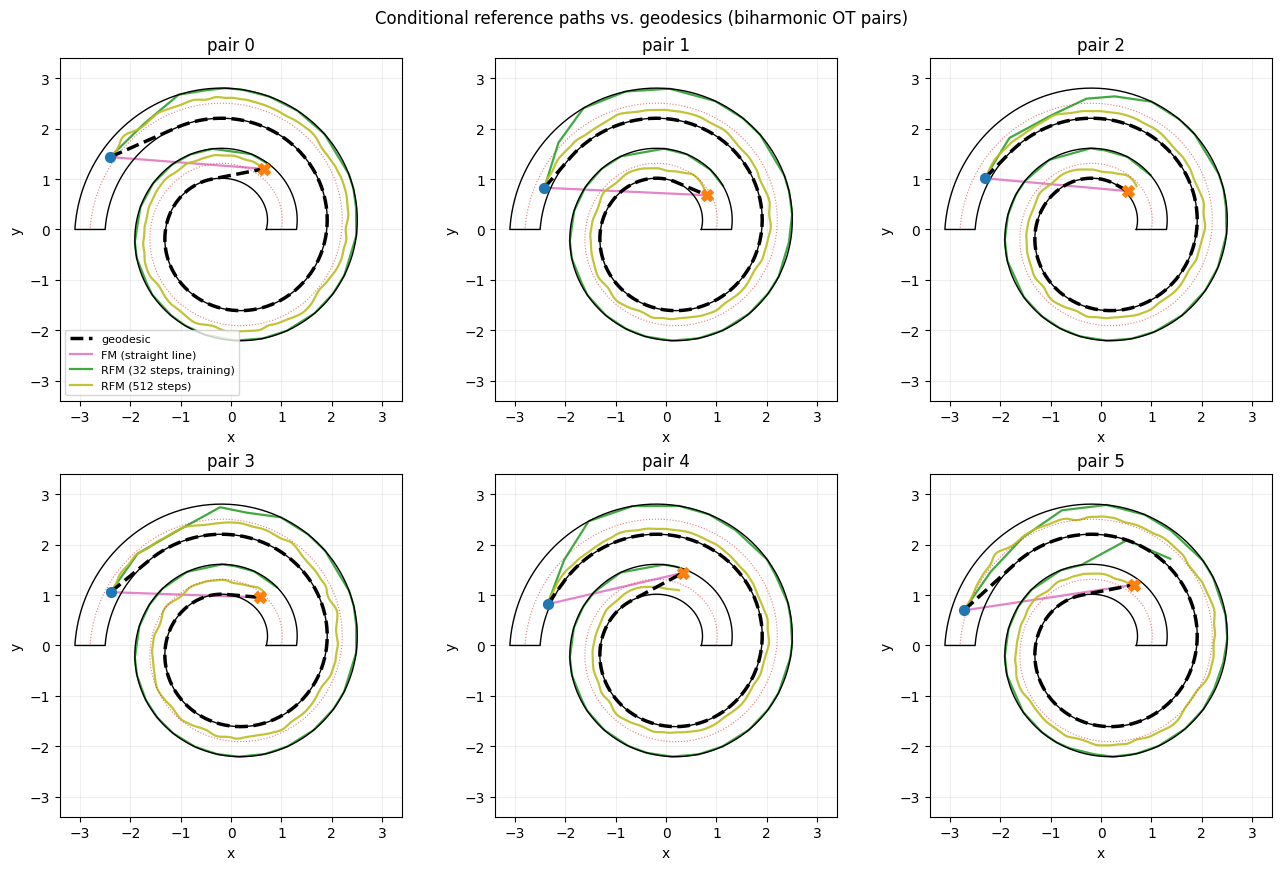

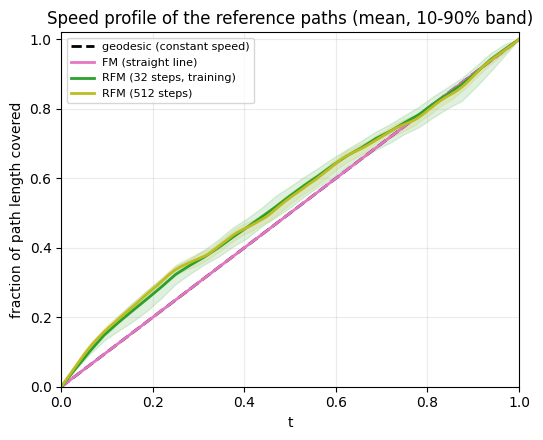

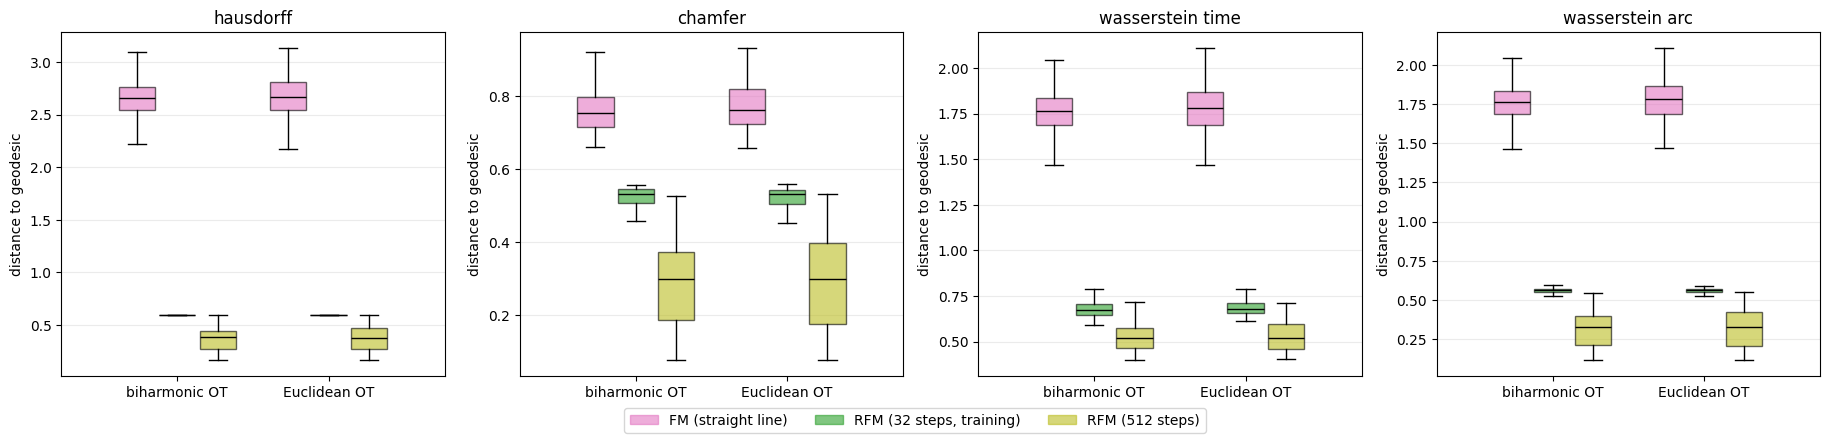

In [12]:
# A few biharmonic-OT pairs; the dashed black curve is the geodesic.
ref_example_coupling = "biharmonic OT"
ref_example_ids = np.arange(6)
reference_paths.plot_reference_paths(
    roll, *ref_pairs[ref_example_coupling],
    {name: paths for name, (_, paths) in ref_paths[ref_example_coupling].items()},
    ref_colors, np.linspace(0.0, 1.0, 400), ref_example_ids,
    title=f"Conditional reference paths vs. geodesics ({ref_example_coupling} pairs)",
)
reference_paths.plot_arc_progress(ref_paths[ref_example_coupling], ref_colors)
reference_paths.plot_distance_distributions(ref_per_pair, ref_colors)

In [13]:
# Same biharmonic-OT pairs, same training interpolation settings, every kernel profile.
ref_kernel_per_pair = {}
x0, x1 = ref_pairs["biharmonic OT"]
for kernel_name, kernel_model in kernel_models.items():
    interpolator = loss_modes.interpolator_like(rfm_cf, kernel_model)
    for steps in (ref_training_steps, ref_fine_steps):
        times, paths = reference_paths.rfm_reference_paths(interpolator, x0, x1, steps)
        ref_kernel_per_pair[kernel_name, f"{steps} steps"] = reference_paths.compare_to_geodesics(
            roll, x0, x1, times, paths
        )
ref_kernel_summary = reference_paths.summarize(ref_kernel_per_pair, stats=("mean", "max"))
display(ref_kernel_summary.T.style.format("{:.3f}", na_rep="–"))

### Reading the reference-path comparison

The geodesics are on average 13.5 long, 4.5 times the straight chord. The taut string hugs the inner (concave) edge of every turn. The two couplings give practically the same numbers, so the discussion uses the biharmonic pairs.

- **FM never follows the roll.** Every straight reference path leaves the roll and crosses the gaps (`leaves_domain` = 1). It is only 23% as long as the geodesic. Its median Hausdorff distance is 2.66: the middle of the geodesic lies far out on the turns that the chord skips.
- **RFM with 512 steps follows the roll closely.** Its median Hausdorff distance is 0.38 and its median Chamfer distance 0.30, against 2.66 and 0.75 for FM. No path leaves the roll. Most of what remains is the taut string's extreme position: it runs along the inner edge, while the RFM paths stay near the centerline, at about half the roll width (0.3). They are 18% longer than the geodesic.
- **The 32-step training paths are noticeably worse.** Each Euler step is about 0.5 long, comparable to the roll width, so the steps overshoot and the projection pins the path to the *outer* edge of the turn. The figure shows this, and Hausdorff sits at almost exactly the roll width 0.6 for nearly every pair. Further consequences:
  - paths are 33% longer than the geodesic;
  - 12% of them cut across a gap between two saved states;
  - they stop 0.33 (median) short of the target, against 0.13 with 512 steps.

  That residual, and the edge-riding, are part of what RFM training regresses.
- **Unlike on the annulus, the speed profile is almost geodesic.** RFM covers 54–55% of its length by $t=0.5$ (50% at constant speed). The time-$W_2$ (0.52 median) is therefore only somewhat larger than the arc-length $W_2$ (0.33). On a long, thin strip, the biharmonic distance grows almost linearly with arc length, so shrinking it linearly in $t$ gives nearly constant Euclidean speed. On the annulus, the same construction covers about 70% of the length by $t=0.5$.
- **Kernel profiles.** With 512 steps, the compact polynomial and the smooth bump are closest to the geodesics (mean Chamfer 0.27, arc-length $W_2$ 0.30), followed by the fixed and variable Gaussians. The variable Gaussian has the smallest endpoint error (0.08). Its speed is strongly front-loaded, though (84% of the length by $t=0.5$), so it has by far the worst time-$W_2$ (0.98). With 32 steps, 8–27% of the paths of every smooth profile cut across a gap; the polynomial is worst and the bump best. The fixed Gaussian used in training has the lowest time-$W_2$ at both step counts. Binary CkNN paths do not move.

These numbers describe the reference targets that the networks regress, independently of training. They also explain part of the four-way comparison: the RFM models learn paths that respect the roll but are longer than necessary, and with 32 interpolation steps they also learn targets that ride the outer edge and stop short of $x_1$.

## RFM loss: final interpolation point vs. every interpolation point

The RFM models above use `loss_mode="final"`. For each pair $(x_0, x_1)$ and sampled time $t\sim U[0,1)$, the solver integrates the RFM field from $0$ to $t$ in $K$ Euler steps. Only the last state enters the loss:

$$\mathcal{L}_{\text{final}}=\mathbb{E}_{t,(x_0,x_1)}\,\big\|v_\theta(t,x_t)-u_t(x_t\mid x_1)\big\|^2 .$$

The other $K-1$ intermediate states are computed and then discarded. `loss_mode="trajectory"` instead regresses the field at **every** Euler state of one integration. It has two variants:

| Variant | Solver arguments | Supervised states per pair |
| --- | --- | --- |
| Random-offset grid | `trajectory_end_time=None` | $t_k=(t+k)/K$, $k=0,\dots,K-1$; the sampled $t$ only shifts the grid, so the times cover $[0,1)$ uniformly |
| Fixed grid to $T$ | `trajectory_end_time=T` | $t_k=kT/K$, $k=0,\dots,K$, including start and end; the sampled $t$ is ignored |

$$\mathcal{L}_{\text{traj}}=\mathbb{E}_{(x_0,x_1)}\,\frac{1}{|\{t_k\}|}\sum_{k}\big\|v_\theta(t_k,x_{t_k})-u_{t_k}(x_{t_k}\mid x_1)\big\|^2 .$$

Per pair and iteration, all variants evaluate the RFM field about $K{+}1$ times. The trajectory loss turns those evaluations into $K$ or $K{+}1$ regression targets instead of one. Targets along one path are correlated.

This section has two parts:

1. **Single-run illustration** ($K=32$, random-offset grid, both couplings). It reuses the four-way comparison setup and shows fields, endpoints, and paths.
2. **Multi-seed comparison with timing** (biharmonic coupling, 3 seeds). It covers $K=32$ with the random-offset grid, and $K=100$ with both the random-offset grid and the fixed grid to $T=0.99$. **Draw conclusions from this part**; the single run is one draw.

Run the four-way comparison cells above first.

### Single-run illustration ($K=32$, random-offset grid)

This run uses `CellFlow.train`, which fixes its batch and time-sampling RNGs. The model seed therefore changes only the network initialization, and the result below is one draw. Compare it with the multi-seed results further down before drawing conclusions.

In [27]:
cmp_loss_modes = ["final", "trajectory"]
lm_couplings = {"biharmonic OT": match_biharmonic, "Euclidean OT": match_euclidean}

# The final-point models are the two RFM models trained in the four-way comparison.
lm_models = {("final", "biharmonic OT"): rfm_cf, ("final", "Euclidean OT"): rfm_euclidean_cf}
lm_losses = {
    ("final", "biharmonic OT"): cmp_losses["RFM + biharmonic OT"],
    ("final", "Euclidean OT"): cmp_losses["RFM + Euclidean OT"],
}
lm_training_seconds = {
    ("final", "biharmonic OT"): cmp_training_seconds["RFM + biharmonic OT"],
    ("final", "Euclidean OT"): cmp_training_seconds["RFM + Euclidean OT"],
}
assert all(model.solver.loss_mode == "final" for model in lm_models.values())

for coupling_name, match_fn in lm_couplings.items():
    key = ("trajectory", coupling_name)
    lm_models[key] = flows.build_matched_model(
        rfm_cf, rfm_adata, "otrfm", match_fn, rfm_target_key, cmp_seed, nystroem=rfm_nystroem,
        solver_kwargs={"loss_mode": "trajectory"},
    )
    print(f"Training RFM, trajectory loss, {coupling_name}", flush=True)
    lm_losses[key], lm_training_seconds[key] = flows.train_timed(lm_models[key], cmp_num_iterations, cmp_batch_size)

lm_order = [(mode, coupling) for coupling in lm_couplings for mode in cmp_loss_modes]
display(pd.DataFrame({
    "training_seconds": lm_training_seconds,
    "mean_loss_first_25": {key: losses[:25].mean() for key, losses in lm_losses.items()},
    "mean_loss_last_25": {key: losses[-25:].mean() for key, losses in lm_losses.items()},
}).loc[lm_order].rename_axis(["loss_mode", "coupling"]))

[                                        ] | 0% Completed | 160.72 us

[########################################] | 100% Completed | 102.14 ms

[                                        ] | 0% Completed | 189.28 us

[########################################] | 100% Completed | 102.19 ms

Training RFM, trajectory loss, biharmonic OT


  0%|          | 0/300 [00:00<?, ?it/s]

... (609 outputs left out)

100%|█████████▉| 299/300 [04:10<00:00,  1.26it/s, loss=15.2]

100%|██████████| 300/300 [04:11<00:00,  1.26it/s, loss=15.2]

100%|██████████| 300/300 [04:11<00:00,  1.19it/s, loss=15.2]

,,training_seconds,mean_loss_first_25,mean_loss_last_25
loss_mode,coupling,,,
final,biharmonic OT,281.790170,142.410206,16.183387
trajectory,biharmonic OT,253.370601,144.557905,14.171178
final,Euclidean OT,264.871741,144.001247,15.987622
trajectory,Euclidean OT,251.763554,144.689193,14.153621


#### Field error against the exact RFM target

Training losses are noisy single-batch estimates. For a cleaner comparison, every model is evaluated on the **same** held-out set of RFM states. We draw 512 source–target pairs from each coupling over the full clouds and integrate the exact RFM field with the training interpolator. The time grids use random offsets, and the comparison records the squared error $\|v_\theta-u_t\|^2$ at every state. One shared set of states is used per coupling, so the two loss modes see identical queries. The errors are binned by time, because the RFM target $u_t\propto 1/(1-t)$ grows near $t=1$. Velocity clipping at `max_velocity_norm` bounds that growth.

In [28]:
lm_eval_pairs = 512
lm_eval_rng = np.random.default_rng(cmp_seed + 1)
lm_eval_interpolator = loss_modes.interpolator_like(rfm_cf, rfm_nystroem)
lm_full_couplings = {"biharmonic OT": cmp_couplings["biharmonic"], "Euclidean OT": cmp_couplings["Euclidean"]}
lm_eval_states = {
    coupling_name: loss_modes.sample_rfm_eval_states(
        lm_eval_interpolator, coupling, rfm_source, rfm_target, lm_eval_pairs,
        rfm_cf.solver.interpolation_steps, lm_eval_rng,
    )
    for coupling_name, coupling in lm_full_couplings.items()
}

lm_time_bins = np.linspace(0.0, 1.0, 11)
lm_field_rows, lm_binned_errors = [], {}
for (mode, coupling_name), model in lm_models.items():
    metrics, lm_binned_errors[mode, coupling_name] = loss_modes.field_error(
        model, lm_eval_states[coupling_name], lm_time_bins
    )
    lm_field_rows.append({"loss_mode": mode, "coupling": coupling_name, **metrics})
lm_field_df = pd.DataFrame(lm_field_rows).set_index(["loss_mode", "coupling"]).loc[lm_order]
display(lm_field_df)

,,field_mse,field_mse_t<0.9,median_relative_error,mean_cosine_similarity
loss_mode,coupling,,,,
final,biharmonic OT,15.983046,13.305586,0.232953,0.989866
trajectory,biharmonic OT,14.492142,11.725067,0.218635,0.991380
final,Euclidean OT,15.703687,13.300551,0.234040,0.990312
trajectory,Euclidean OT,14.090912,11.656393,0.215434,0.992090


In [29]:
# Endpoint metrics on the fitted source cloud and path metrics on the shared fresh samples.
lm_predicted, lm_trajectories, lm_rows = {}, {}, []
for key, model in lm_models.items():
    lm_predicted[key], lm_trajectories[key], metrics = loss_modes.endpoint_and_path_metrics(
        model, rfm_adata, rfm_target_key, rfm_condition, rfm_target, roll,
        cmp_new_start_points, cmp_trajectory_times,
    )
    lm_rows.append({"loss_mode": key[0], "coupling": key[1], **metrics})
np.testing.assert_allclose(lm_predicted["final", "biharmonic OT"], cmp_predicted["RFM + biharmonic OT"], atol=1e-4)
lm_endpoint_df = pd.DataFrame(lm_rows).set_index(["loss_mode", "coupling"]).loc[lm_order]

lm_summary = lm_endpoint_df[[
    "energy_distance_squared", "mean_error_to_target", "outside_roll_fraction",
    "mean_roll_violation", "paths_leaving_roll", "fraction_saved_points_in_roll",
    "max_segment_gap_penetration",
]].join(lm_field_df[["field_mse", "field_mse_t<0.9", "mean_cosine_similarity"]])
lm_summary["training_seconds"] = [lm_training_seconds[key] for key in lm_summary.index]
display(lm_summary)

[                                        ] | 0% Completed | 148.93 us

[########################################] | 100% Completed | 101.48 ms

[                                        ] | 0% Completed | 191.53 us

[########################################] | 100% Completed | 101.24 ms

[                                        ] | 0% Completed | 158.42 us

[########################################] | 100% Completed | 101.60 ms

... (7 outputs left out)

[########################################] | 100% Completed | 101.72 ms

[                                        ] | 0% Completed | 121.37 us

[########################################] | 100% Completed | 100.93 ms

,,energy_distance_squared,mean_error_to_target,outside_roll_fraction,mean_roll_violation,paths_leaving_roll,fraction_saved_points_in_roll,max_segment_gap_penetration,field_mse,field_mse_t<0.9,mean_cosine_similarity,training_seconds
loss_mode,coupling,,,,,,,,,,,
final,biharmonic OT,0.783824,0.632101,0.000,0.000000,0,1.0,0.0,15.983046,13.305586,0.989866,281.790170
trajectory,biharmonic OT,0.296443,0.335512,0.000,0.000000,0,1.0,0.0,14.492142,11.725067,0.991380,253.370601
final,Euclidean OT,0.708504,0.590593,0.008,0.000063,0,1.0,0.0,15.703687,13.300551,0.990312,264.871741
trajectory,Euclidean OT,0.332042,0.360600,0.000,0.000000,0,1.0,0.0,14.090912,11.656393,0.992090,251.763554


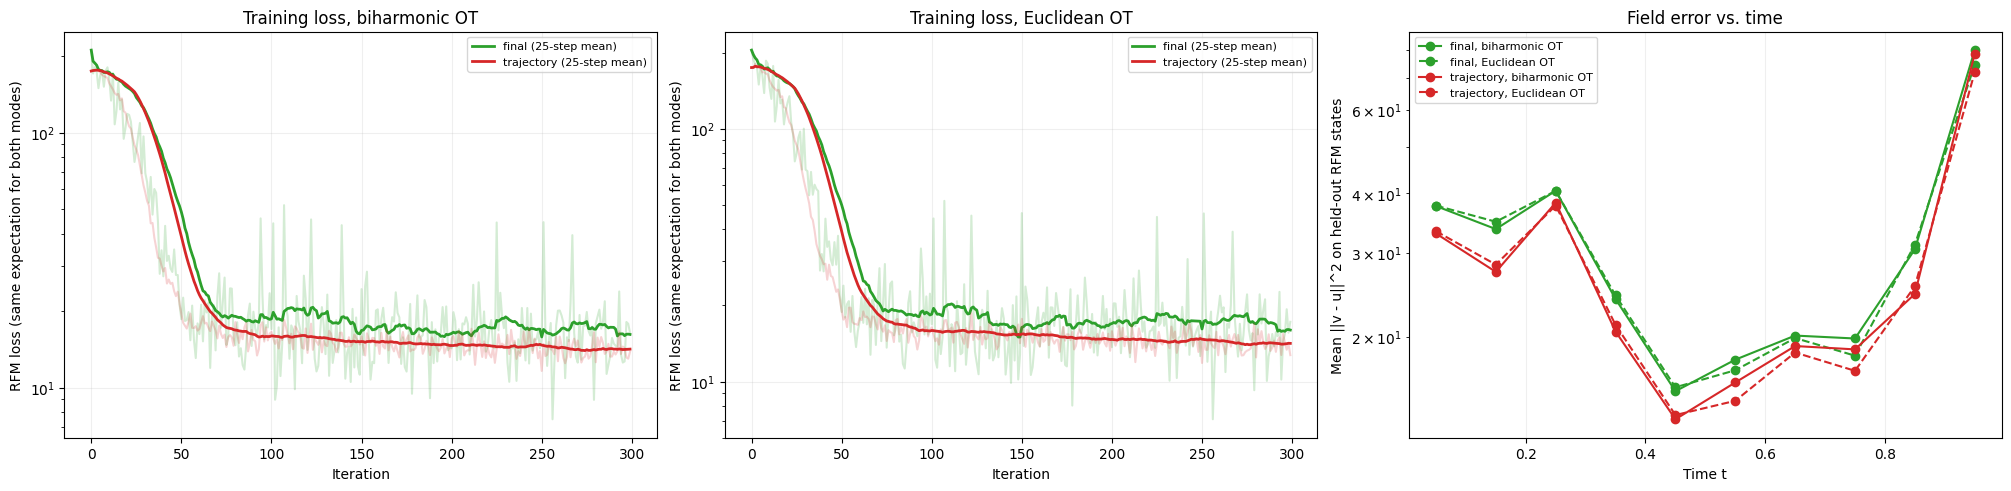

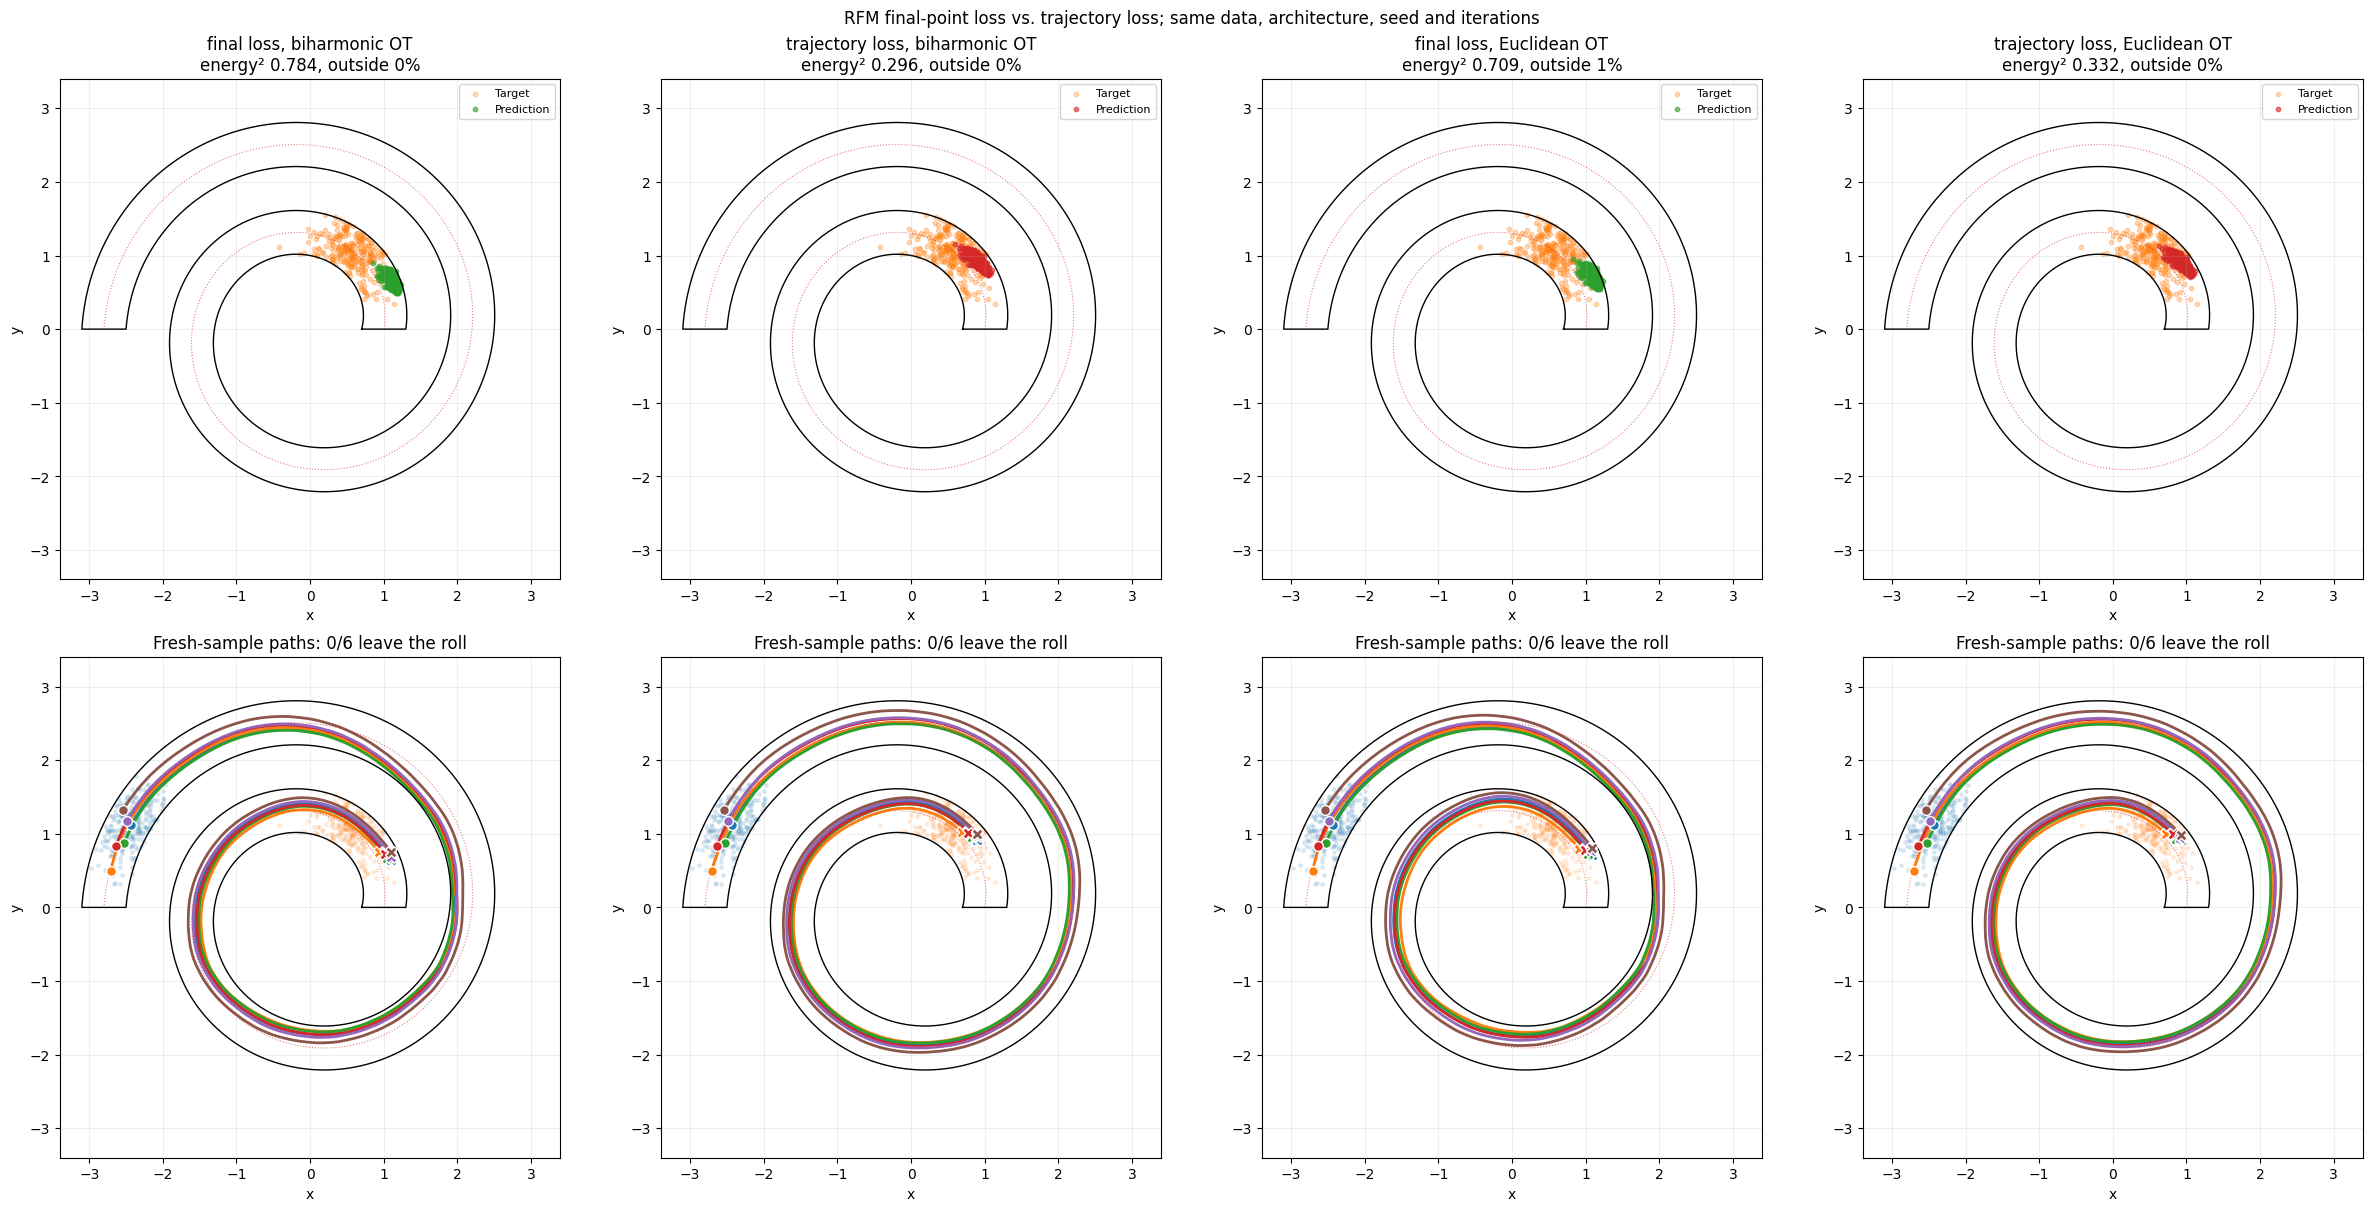

In [30]:
loss_modes.plot_single_run(
    lm_losses, lm_binned_errors, lm_time_bins, lm_couplings, lm_predicted, lm_trajectories, lm_summary,
    roll, rfm_source, rfm_target,
)

### Multi-seed comparison and computation time

The run below varies the seed over $\{2026, 1, 2\}$ and drives `solver.step_fn` directly in the same loop as `CellFlowTrainer.train`, without validation. Batches, time samples, and network initialization all depend on the seed. All models use the biharmonic coupling, the network and optimizer of `rfm_cf`, batch size 32, 300 iterations, roll projection, and velocity clipping at 30.

| Setting | `interpolation_steps` | Variant | Solver arguments |
| --- | --- | --- | --- |
| 32 steps | 32 | final | `loss_mode="final"`, sampled $t$ |
| 32 steps | 32 | trajectory, random offset | `loss_mode="trajectory"`, `trajectory_end_time=None` |
| 100 steps | 100 | final | `loss_mode="final"`, sampled $t$ |
| 100 steps | 100 | trajectory, fixed grid to 0.99 | `loss_mode="trajectory"`, `trajectory_end_time=0.99` (101 states) |
| 100 steps | 100 | trajectory, random offset | `loss_mode="trajectory"`, `trajectory_end_time=None` |

The two 100-step trajectory variants separate the effect of the step count from the effect of the grid.

Evaluation:

- **Endpoints:** the fitted source cloud, pushed through `predict`.
- **Paths:** 200 fresh source samples from the outer-end Gaussian, integrated with the standard Tsit5 settings and saved at 201 times.
- **Field error:** 512 coupled pairs on random-offset grids with the setting's step count, covering $[0,1)$ uniformly. They are drawn independently of training, so they never coincide with a training state.

Timing:

- **Wall-clock time of each `step_fn` call,** blocked until the result is ready.
- **The first iteration is reported separately,** because it includes JIT compilation.
- **Each configuration ran alone** on an otherwise idle CPU.

Training takes a few hours in total on a CPU. By default, the cell loads the saved results from `riemannian_swiss_roll_rfm_loss_mode_results.json`. Set `lm_run_multiseed = True` to recompute and overwrite them.

In [31]:
lm_run_multiseed = False  # True recomputes (several hours) and overwrites the saved results
lm_results_path = "riemannian_swiss_roll_rfm_loss_mode_results.json"
lm_seeds = [2026, 1, 2]
lm_configs = loss_modes.MULTISEED_CONFIGS  # (setting, variant, interpolation_steps, loss_mode, trajectory_end_time)
lm_metrics = loss_modes.multiseed_metric_names(roll)

lm_rows = loss_modes.load_or_run_multiseed(
    lm_results_path, lm_run_multiseed, lm_configs,
    seeds=lm_seeds, adata=rfm_adata, target_key=rfm_target_key, architecture_kwargs=cmp_architecture_kwargs,
    optimizer=rfm_cf.solver.vf_state.tx, match_fn=match_biharmonic, nystroem=rfm_nystroem, geometry=roll,
    source=rfm_source, target=rfm_target, coupling=np.asarray(rfm_match_jit(rfm_source, rfm_target)),
    fresh_starts=roll.sample_gaussian(
        mean_outer, variance, 200, np.random.default_rng(4242), theta_window=outer_window)[0].astype(np.float32),
)
print(f"{len(lm_rows)} runs ({len(lm_seeds)} seeds each): "
      + "; ".join(f"{setting}, {variant}" for setting, variant, *_ in lm_configs))

15 runs (3 seeds each): 32 steps, final; 32 steps, trajectory, random offset; 100 steps, final; 100 steps, trajectory, fixed grid to 0.99; 100 steps, trajectory, random offset


Results, mean ± sd over seeds (lower is better for every column)


energy_distance_squared  \
setting   variant                                                  
32 steps  final                                     0.14 ± 0.044   
          trajectory, random offset                0.406 ± 0.131   
100 steps final                                    0.178 ± 0.137   
          trajectory, fixed grid to 0.99           0.343 ± 0.154   
          trajectory, random offset                 0.27 ± 0.104   

                                         outside_roll_fraction  \
setting   variant                                                
32 steps  final                                   0.043 ± 0.06   
          trajectory, random offset                  0.0 ± 0.0   
100 steps final                                  0.031 ± 0.053   
          trajectory, fixed grid to 0.99             0.0 ± 0.0   
          trajectory, random offset              0.069 ± 0.061   

                                         fresh_paths_leaving_roll  \
setting   variant                                                   
32 steps  final                                     0.245 ± 0.078   
          trajectory, random offset                 0.057 ± 0.077   
100 steps final                                     0.303 ± 0.196   
          trajectory, fixed grid to 0.99            0.253 ± 0.223   
          trajectory, random offset                    0.13 ± 0.1   

                                         max_gap_penetration       field_mse  \
setting   variant                                                              
32 steps  final                                0.104 ± 0.009  15.933 ± 0.007   
          trajectory, random offset            0.034 ± 0.053  14.019 ± 0.119   
100 steps final                                0.155 ± 0.099  14.919 ± 0.352   
          trajectory, fixed grid to 0.99       0.096 ± 0.073  15.268 ± 0.349   
          trajectory, random offset            0.055 ± 0.029  13.054 ± 0.245   

                                         field_mse_t<0.9  
setting   variant                                         
32 steps  final                           13.377 ± 0.125  
          trajectory, random offset       11.507 ± 0.118  
100 steps final                           13.595 ± 0.389  
          trajectory, fixed grid to 0.99  14.015 ± 0.358  
          trajectory, random offset        11.85 ± 0.225

Seeds (of 3) on which the trajectory variant beats the final-point loss with the same step count


energy_distance_squared  \
setting   variant                                                   
32 steps  trajectory, random offset                             0   
100 steps trajectory, fixed grid to 0.99                        1   
          trajectory, random offset                             1   

                                          outside_roll_fraction  \
setting   variant                                                 
32 steps  trajectory, random offset                           3   
100 steps trajectory, fixed grid to 0.99                      1   
          trajectory, random offset                           0   

                                          fresh_paths_leaving_roll  \
setting   variant                                                    
32 steps  trajectory, random offset                              3   
100 steps trajectory, fixed grid to 0.99                         2   
          trajectory, random offset                              2   

                                          max_gap_penetration  field_mse  \
setting   variant                                                          
32 steps  trajectory, random offset                         3          3   
100 steps trajectory, fixed grid to 0.99                    2          0   
          trajectory, random offset                         2          3   

                                          field_mse_t<0.9  
setting   variant                                          
32 steps  trajectory, random offset                     3  
100 steps trajectory, fixed grid to 0.99                0  
          trajectory, random offset                     3

Computation time at 100 steps, mean ± sd over seeds (seconds)


first_iter_seconds_incl_compile  \
setting   variant                                                          
100 steps final                                             16.93 ± 1.26   
          trajectory, fixed grid to 0.99                     3.54 ± 0.19   
          trajectory, random offset                          3.89 ± 1.25   

                                         median_iter_seconds  \
setting   variant                                              
100 steps final                                  2.61 ± 0.02   
          trajectory, fixed grid to 0.99         2.57 ± 0.01   
          trajectory, random offset              2.61 ± 0.16   

                                         train_seconds_total  
setting   variant                                             
100 steps final                               811.26 ± 11.16  
          trajectory, fixed grid to 0.99       779.21 ± 5.04  
          trajectory, random offset           792.52 ± 40.97

The 32-step runs recorded only build + train + evaluation time per model:


build_train_eval_seconds
setting  variant                                           
32 steps final                                  274.7 ± 1.9
         trajectory, random offset              271.9 ± 2.1

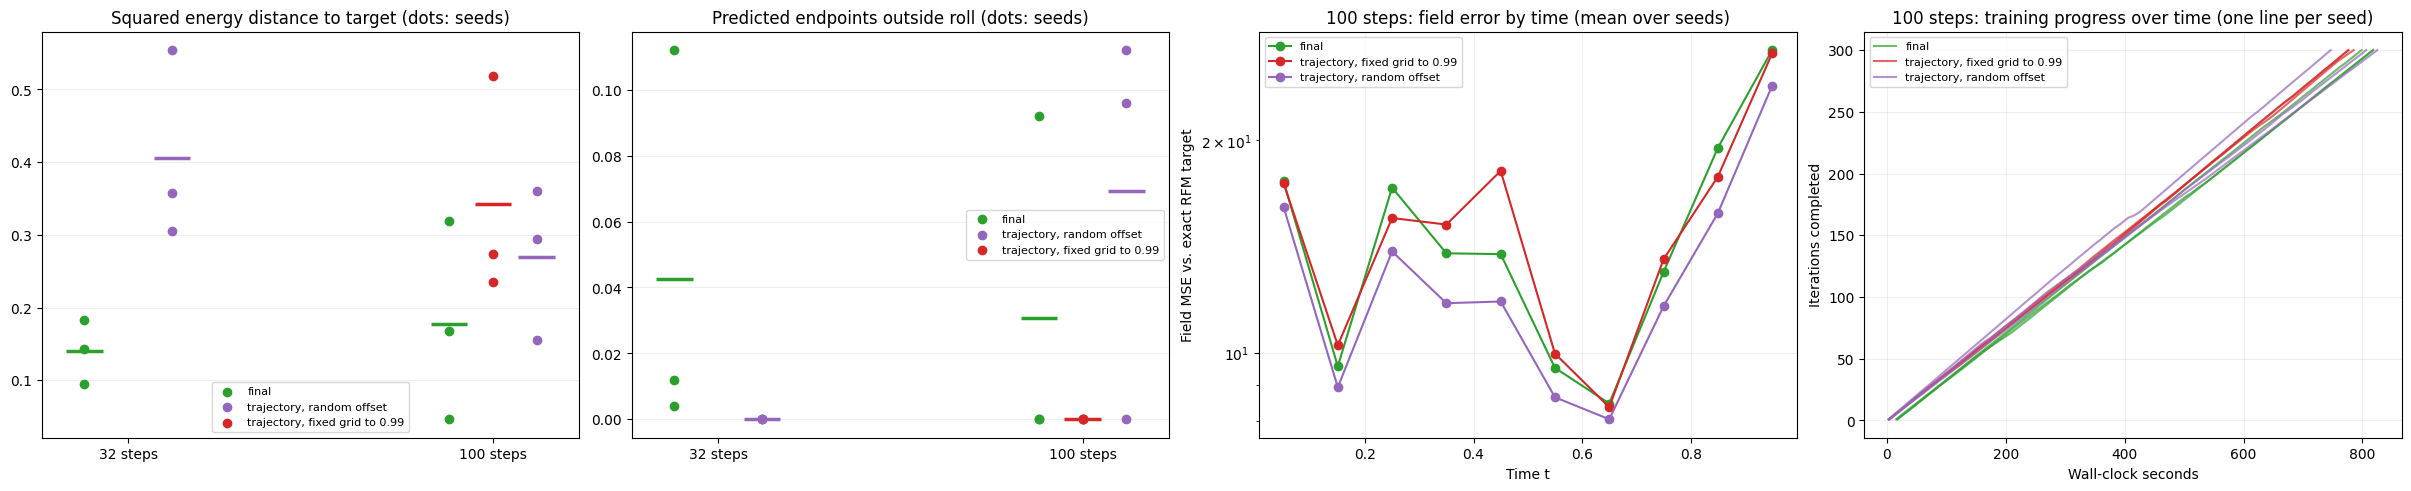

In [32]:
lm_ms = loss_modes.show_multiseed_tables(lm_rows, lm_configs, lm_seeds, metrics=lm_metrics)
loss_modes.plot_multiseed(lm_ms, lm_configs, lm_seeds, geometry_name=roll.name)

### Reading the multi-seed comparison

**32 steps, random-offset grid.** The trajectory loss again fits the RFM field better on every seed: field MSE 14.02 ± 0.12 vs. 15.93 ± 0.01. It also respects the roll much better: endpoints outside the roll are 0 vs. 0.04, fresh paths leaving it 0.06 vs. 0.25, and maximum gap penetration 0.03 vs. 0.10, each better on 3/3 seeds. Its endpoint distribution is worse on every seed: squared energy distance 0.41 ± 0.13 vs. 0.14 ± 0.04. The single-run illustration above shows the opposite ranking (0.30 vs. 0.78). That run uses `CellFlow.train` with its fixed batch and time RNGs, and the final-point model in it is an unfavourable draw: the seeded final-point runs reach 0.10–0.18.

**100 steps.** Mean ± sd over 3 seeds; per-seed wins are against the final-point loss.

| Metric (lower is better) | final | trajectory, fixed grid to 0.99 | trajectory, random offset |
| --- | --- | --- | --- |
| Squared energy distance | **0.18 ± 0.14** | 0.34 ± 0.15 (1/3) | 0.27 ± 0.10 (1/3) |
| Endpoints outside roll | 0.031 | **0.000** (1/3) | 0.069 (0/3) |
| Fresh paths leaving roll | 0.30 | 0.25 (2/3) | **0.13** (2/3) |
| Max gap penetration | 0.16 ± 0.10 | 0.10 ± 0.07 (2/3) | **0.06 ± 0.03** (2/3) |
| Field MSE | 14.92 | 15.27 (0/3) | **13.05 ± 0.25** (3/3) |

- **The random-offset grid repeats the 32-step pattern:** it has the lowest field error on every seed and the fewest paths crossing a gap, but a worse endpoint distribution. Ties at 0 count as no win, so the endpoint-outside wins understate the fixed grid. It has no endpoints outside the roll on any seed; the final-point loss has them on one.
- **The fixed grid to 0.99 does not improve the field fit** (worse on all seeds). Its geometric gains are inconsistent across seeds: one seed has 46% of fresh paths leaving the roll, another 2%.
- **The seed spread is large.** For example, final-point energy ranges from 0.05 to 0.32 at 100 steps. Three seeds separate only the field MSE and the 32-step comparisons cleanly.
- **Cost:** at 100 steps, all three variants take about 2.6 s per iteration (13–14 min per run). The trajectory loss adds no measurable cost, because the interpolation dominates. Only the first iteration of the final-point loss is slower (17 s vs. 4 s), because of compilation.